# Chiller Plant Model Training & Validation

**Project:** CSIT SP2, Science Park Road. Advisory AI/ML reset of the chilled-water supply (CHWS) setpoint and the cooling-tower (CT) leaving-water setpoint, as described in the *OptimusAI AI/ML Document, Rev 1 (16 Oct 2026)* in `document/`.

The advisory engine (document Section 7) is built from six models fitted on plant data: cooling-demand forecast, weather forecast at the towers, chiller performance curve (one per chiller), cooling-tower model, pump and fan curves, and the savings baseline. This notebook prepares the data those models are trained and validated on.

| Part | Content | Status |
|---|---|---|
| 1 | Environment setup and loading the original GitHub model code | this notebook |
| 2 | Dataset loading and analysis: columns, missing values, time intervals, measurement quality | this notebook |
| 3 | Cleaning, unit conversion, resampling, feature engineering, chronological splits | this notebook |
| 4 – 9 | Models 1 – 6: cooling load, weather, chiller power, cooling tower, pump and fan power, energy baseline | trained where the data allow; Models 4 and 5 wait for data |
| 10 | Accuracy comparison against the Section 7 targets | this notebook |
| 11 | Results export for the report | this notebook |

| Dataset | File in `latest_data/` | Content |
|---|---|---|
| **UWCSEA** | `HVAC Energy Data.csv` | 30-min chiller-plant and weather log, Aug 2019 to Jun 2020 |
| **NEA** | `HistoricalAirTemperatureacrossSingapore.zip` | 1-min dry-bulb readings from the NEA station network, 2016 to 2024 (nine yearly CSVs, about 10 GB unzipped) |
| **CSIT** | `csit_datatable.csv` | 1-min Honeywell BMS trend export from the target plant, Sep to Oct 2026 |

## 1. Environment Setup

### 1.1 Install libraries
Installs only the packages that are missing from the active kernel.

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {  # import name -> pip package
    "numpy": "numpy", "pandas": "pandas", "pyarrow": "pyarrow", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "sklearn": "scikit-learn", "statsmodels": "statsmodels",
    "lightgbm": "lightgbm", "joblib": "joblib",
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", " ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required libraries are already installed.")

All required libraries are already installed.


### 1.2 Imports and configuration
Plant facts and control limits are taken from the AI/ML Document (Sections 2, 3, 5, 7 and 8) so that later sections can check data and recommendations against them.

In [2]:
import ast, json, math, re, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import sklearn, statsmodels, lightgbm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

# Paths (the notebook sits at the repository root)
ROOT = Path.cwd()
if not (ROOT / "latest_data").exists() and (ROOT.parent / "latest_data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "latest_data"
CODE_DIR = ROOT / "original_code"
OUT_DIR = ROOT / "processed_data"
CACHE_DIR = OUT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

UWCSEA_FILE = DATA_DIR / "HVAC Energy Data.csv"
CSIT_FILE = DATA_DIR / "csit_datatable.csv"
NEA_ZIP = DATA_DIR / "HistoricalAirTemperatureacrossSingapore.zip"

LOCAL_TZ = "Asia/Singapore"
KW_PER_RT = 3.51685   # 1 refrigeration ton = 3.51685 kW thermal
CP_WATER = 4.186      # kJ/(kg K)
RHO_WATER = 1.0       # kg/L, chilled and condenser water

# CSIT SP2 plant and control limits from the AI/ML Document
PLANT = {
    "n_chillers": 3, "chiller_capacity_rt": 300,            # Daikin HXEV490TSTGG magnetic-bearing centrifugal
    "chw_pump_design_lps": 36, "cw_pump_design_lps": 52,    # Paragon PA-100-32 / PA-125-26
    "ct_capacity_rt": 340, "ct_fan_speed_pct": (40, 100),   # Truwater iVXS-2220A-3LIA, EC fans
    "chws_setpoint_today_c": 10.0, "chws_setpoint_range_c": (10.0, 11.5),
    "ct_setpoint_range_c": (23.0, 29.5), "ct_min_approach_to_wb_c": 2.0,
    "ct_formula_today": {"a": 0.5, "b": 27.0},              # 0.5 x wet-bulb + 27, clipped to the range
    "decision_interval": "15min", "test_window_days": 14,
}
# Accuracy targets on the test days (Section 7)
ACCURACY_TARGETS = pd.DataFrame([
    ("Cooling demand forecast", "cooling load, next hour in 15-min steps", "within 5 %"),
    ("Weather forecast at the towers", "outdoor temperature and humidity, next hour", "within 1 °C"),
    ("Chiller performance curve", "chiller kW", "within 3 %"),
    ("Cooling tower model", "tower leaving water temperature", "within 0.3 °C"),
    ("Pump and fan curves", "pump kW and fan kW", "within 3 %"),
    ("Baseline", "plant kW at today's setpoints", "within 5 %"),
], columns=["model", "output", "target"])

for lib in (np, pd, sklearn, statsmodels, lightgbm, sns):
    print(f"{lib.__name__:<12}{lib.__version__}")
print("ROOT:", ROOT)
ACCURACY_TARGETS

numpy       2.4.3
pandas      3.0.5
sklearn     1.9.0
statsmodels 0.15.0
lightgbm    4.7.0
seaborn     0.13.2
ROOT: D:\GitHub\Roycemedia\model-validation-v1


,model,output,target
0,Cooling demand forecast,"cooling load, next hour in 15-min steps",within 5 %
1,Weather forecast at the towers,"outdoor temperature and humidity, next hour",within 1 °C
2,Chiller performance curve,chiller kW,within 3 %
3,Cooling tower model,tower leaving water temperature,within 0.3 °C
4,Pump and fan curves,pump kW and fan kW,within 3 %
5,Baseline,plant kW at today's setpoints,within 5 %


### 1.3 Load the existing GitHub model code
The original modelling work (repository `altotech-ml-hvac-test`, copied into `original_code/`) was developed on a different, five-chiller dataset (`deprecate_data/chiller_plant_dataset.parquet`). Its notebooks mix function definitions with training runs on that old data, so they are not run top to bottom here. Instead the notebook:

1. inventories each notebook (sections, estimators used);
2. loads every top-level function and class those notebooks define into a namespace `orig`, without running any training or data loading;
3. carries the original model forms, hyper-parameters, preprocessing choices and metric forward, so Part 4 can benchmark new models against them.

In [3]:
ESTIMATOR_PATTERN = (r"\b(LinearRegression|Ridge|RandomForestRegressor|MLPRegressor|SARIMAX|"
                     r"NARXModel|DQNAgent|DoubleDQNAgent|PPO\w*|minimize)\b")


def read_notebook(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def summarise_notebook(path):
    cells = read_notebook(path)["cells"]
    code_src = "\n".join("".join(c["source"]) for c in cells if c["cell_type"] == "code")
    headings = [line.lstrip("#").strip()
                for c in cells if c["cell_type"] == "markdown"
                for line in "".join(c["source"]).splitlines() if line.startswith("#")]
    return {
        "notebook": Path(path).name,
        "cells": len(cells),
        "code_cells": sum(c["cell_type"] == "code" for c in cells),
        "estimators": ", ".join(sorted(set(re.findall(ESTIMATOR_PATTERN, code_src)))),
        "data_source": ", ".join(sorted(set(re.findall(r"read_parquet\('([^']+)'\)", code_src)))),
        "first_sections": " | ".join(headings[:5]),
    }


ORIGINAL_NOTEBOOKS = sorted(CODE_DIR.glob("*.ipynb"))
inventory = pd.DataFrame([summarise_notebook(p) for p in ORIGINAL_NOTEBOOKS])
inventory

,notebook,cells,code_cells,estimators,data_source,first_sections
0,analyze_data.ipynb,85,54,"LinearRegression, NARXModel, RandomForestRegre...",../data/chiller_plant_dataset.parquet,Preprocessing | Drop columns | Cleaning missin...
1,mpc.ipynb,64,37,"LinearRegression, MLPRegressor, RandomForestRe...",chiller_data_pre.parquet,Create predictive model | Chiller cooling rate...
2,problem1.ipynb,40,21,"LinearRegression, RandomForestRegressor, SARIMAX","../data/chiller_plant_dataset.parquet, chiller...",Preprocessing | Load preprocessed data | Sys i...
3,rl_control.ipynb,33,28,"DQNAgent, DoubleDQNAgent, RandomForestRegressor","../data/chiller_plant_dataset.parquet, chiller...",Prepare Data | Load plant power prediction mod...
4,system_iden.ipynb,31,17,"LinearRegression, Ridge, SARIMAX","../data/chiller_plant_dataset.parquet, chiller...",Prepare data | Load pre-processed data | EDA |...


In [4]:
def load_definitions(paths):
    """Execute only the top-level def/class statements (and the imports of the same cell) of each notebook.

    Training loops, data loading and plotting are skipped. When a name is defined more than once,
    the last definition wins, as it would in the original notebooks.
    """
    namespace, log = {}, []
    for path in paths:
        for i, cell in enumerate(read_notebook(path)["cells"]):
            if cell["cell_type"] != "code":
                continue
            try:
                tree = ast.parse("".join(cell["source"]))
            except SyntaxError:
                continue
            defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef))]
            if not defs:
                continue
            for node in (n for n in tree.body if isinstance(n, (ast.Import, ast.ImportFrom))):
                try:
                    exec(compile(ast.Module([node], []), path.name, "exec"), namespace)
                except Exception:
                    pass  # e.g. torch or plotly not installed; dependent classes are reported below
            for node in defs:
                try:
                    exec(compile(ast.Module([node], []), path.name, "exec"), namespace)
                    status = "loaded"
                except Exception as exc:
                    status = f"not loaded: {type(exc).__name__}: {exc}"
                log.append({"notebook": path.name, "cell": i,
                            "kind": "class" if isinstance(node, ast.ClassDef) else "function",
                            "name": node.name, "status": status})
    return namespace, pd.DataFrame(log)


orig_ns, orig_log = load_definitions(ORIGINAL_NOTEBOOKS)
orig_defs = orig_log.drop_duplicates("name", keep="last").reset_index(drop=True)
print(f"{len(orig_log)} definitions found, {orig_defs['name'].nunique()} unique names, "
      f"{(orig_defs['status'] == 'loaded').sum()} loaded")
orig_defs.groupby(["notebook", "kind", "status"]).agg(n=("name", "size"), names=("name", ", ".join))

66 definitions found, 41 unique names, 39 loaded


n                                              names
notebook           kind     status                                                                                                
analyze_data.ipynb class    not loaded: NameError: name 'nn' is not defined   1                                          NARXModel
                   function loaded                                            1                             create_lagged_features
mpc.ipynb          class    loaded                                            1                               ChillerChangeTracker
                   function loaded                                           27  train_and_evaluate_linear_regression, train_an...
rl_control.ipynb   class    loaded                                            6  Chiller, Pump, CoolingTower, DoubleDQNAgent, C...
                            not loaded: NameError: name 'nn' is not defined   1                                                DQN
                   function loaded                                            3           extract_day, train_agent, evaluate_agent
system_iden.ipynb  function loaded                                            1                                             cvrmse

In [5]:
class OriginalCode:
    """Attribute access to the definitions loaded from original_code/ (e.g. orig.cvrmse)."""

    def __init__(self, namespace, names):
        self._ns, self._names = namespace, sorted(names)

    def __getattr__(self, name):
        if name in self._names:
            return self._ns[name]
        raise AttributeError(name)

    def __dir__(self):
        return self._names


orig = OriginalCode(orig_ns, orig_defs.loc[orig_defs["status"] == "loaded", "name"])

# Smoke test: the original CV(RMSE) metric runs on the new stack
y_true, y_pred = np.array([100.0, 120.0, 90.0]), np.array([98.0, 125.0, 91.0])
print("orig.cvrmse ->", round(float(orig.cvrmse(y_true, y_pred)), 4))
print("Original MPC helpers available:", [n for n in dir(orig) if n in
      ("chiller_power", "chp_power", "cdp_power", "ct_power", "objective", "mpc_control")])

orig.cvrmse -> 0.0306
Original MPC helpers available: ['cdp_power', 'chiller_power', 'chp_power', 'ct_power', 'mpc_control', 'objective']


**The original recipe**, as found in the code. These choices are kept as the benchmark; Part 3 replaces the preprocessing choices marked ✗ because they leak information or hide sensor faults.

In [6]:
ORIGINAL_RECIPE = pd.DataFrame([
    ("Train/test split", "first 60 % train, last 40 % test, chronological, no validation set",
     "✗ replaced by train / validation / test with the most recent days held out (Section 7)"),
    ("Missing values", "forward-fill then back-fill across gaps of any length",
     "✗ replaced by interpolation of short gaps only; long gaps stay missing"),
    ("Negative readings", "set to NaN then forward-filled",
     "✗ replaced by meter-noise rule: small negatives to 0, large negatives removed"),
    ("Chiller power features", "CHWS temp, CHW flow, CW flow, cooling rate, squares and interactions",
     "kept as candidate feature set where the tags exist"),
    ("Models", "LinearRegression, Ridge(alpha=1), RandomForest(400 trees, depth 30), MLP(200), SARIMAX(2,1,3)",
     "kept as benchmark model zoo"),
    ("Metrics", "MSE, MAE, R², CV(RMSE)", "kept, plus the Section 7 percentage targets"),
], columns=["item", "original code", "this notebook"])


def original_model_zoo(seed=SEED):
    """Estimators with the hyper-parameters used in original_code/ (mpc.ipynb, rl_control.ipynb, system_iden.ipynb)."""
    return {
        "linear_regression": LinearRegression(),
        "ridge": Ridge(alpha=1.0),
        "random_forest": RandomForestRegressor(n_estimators=400, max_depth=30, min_samples_split=10,
                                               min_samples_leaf=6, bootstrap=True, random_state=seed, n_jobs=-1),
        "mlp": make_pipeline(StandardScaler(),
                             MLPRegressor(hidden_layer_sizes=(200,), max_iter=2000, random_state=seed)),
    }


ORIGINAL_SARIMAX_ORDER = (2, 1, 3)
display(ORIGINAL_RECIPE)
print("Benchmark zoo:", list(original_model_zoo()))

,item,original code,this notebook
0,Train/test split,"first 60 % train, last 40 % test, chronologica...",✗ replaced by train / validation / test with t...
1,Missing values,forward-fill then back-fill across gaps of any...,✗ replaced by interpolation of short gaps only...
2,Negative readings,set to NaN then forward-filled,✗ replaced by meter-noise rule: small negative...
3,Chiller power features,"CHWS temp, CHW flow, CW flow, cooling rate, sq...",kept as candidate feature set where the tags e...
4,Models,"LinearRegression, Ridge(alpha=1), RandomForest...",kept as benchmark model zoo
5,Metrics,"MSE, MAE, R², CV(RMSE)","kept, plus the Section 7 percentage targets"


Benchmark zoo: ['linear_regression', 'ridge', 'random_forest', 'mlp']


**Feature availability.** The original models were fitted on per-chiller temperatures and flows. The table maps each original feature to the tags that carry it in the new datasets; Part 2 checks how much usable history each one has.

In [7]:
FEATURE_MAP = pd.DataFrame([
    ("chiller_{i}_power", "chiller kW", "plant chiller energy only (Chiller Energy Consumption)", "CH1.kW, CH2.kW, CH3.kW", "-"),
    ("chiller_{i}_cooling_rate / plant_cooling_rate", "cooling load", "Building Load (RT)", "CH.BldgLoad_Ton (plant)", "CHx.BTU_CHW_Ton_Sh"),
    ("chiller_{i}_evap_leaving_water_temperature", "CHWS temperature, the setpoint lever", "-", "-", "CHx.CHWS_Temp, CHLR.DL_HDRCHWS_Temp_Sh"),
    ("chiller_{i}_evap_entering_water_temperature", "CHWR temperature", "-", "-", "CHx.CHWR_Temp, CHLR.DL_HDRCHWR_Temp_Sh"),
    ("chiller_{i}_cond_entering_water_temperature", "CWS temperature, the tower lever", "Cooling Water Temperature (C)", "-", "CHx.CWS_Temp, CHLR.DL_HDRCWS_Temp_Sh"),
    ("chiller_{i}_cond_leaving_water_temperature", "CWR temperature", "-", "-", "CHx.CWR_Temp, CHLR.DL_HDRCWR_Temp_Sh"),
    ("chiller_{i}_evap_water_flow_rate", "CHW flow", "Chilled Water Rate (L/sec), plant", "-", "CHx.CHW_Flow, FLOTECH.CHx_CHW_Flow"),
    ("chiller_{i}_cond_water_flow_rate", "CW flow", "-", "-", "CHx.CW_Flow, FLOTECH.CHx_CW_Flow"),
    ("chiller_{i}_status_read", "run status", "-", "derived from CHx.kW", "-"),
    ("outdoor_weather_station_drybulb_temperature", "outdoor dry-bulb", "Outside Temperature (F); NEA", "NEA climatology only", "OA_WetBulbT.Temp"),
    ("outdoor_weather_station_relative_humidity", "outdoor RH", "Humidity (%)", "-", "OA_WetBulbT.Rh"),
    ("outdoor_weather_station_wetbulb_temperature", "outdoor wet-bulb", "derived from T and dew point", "-", "OA_WetBulbT.WetBulb_Temp"),
    ("plant_power_all_chps / cdps / cts", "pump and tower kW", "-", "CHWP / CWP / CT.PMKWtotal and units", "-"),
], columns=["original feature", "meaning", "UWCSEA", "CSIT trend (Sep-Oct 2026)", "CSIT snapshot only (15 Oct)"])
FEATURE_MAP

,original feature,meaning,UWCSEA,CSIT trend (Sep-Oct 2026),CSIT snapshot only (15 Oct)
0,chiller_{i}_power,chiller kW,plant chiller energy only (Chiller Energy Cons...,"CH1.kW, CH2.kW, CH3.kW",-
1,chiller_{i}_cooling_rate / plant_cooling_rate,cooling load,Building Load (RT),CH.BldgLoad_Ton (plant),CHx.BTU_CHW_Ton_Sh
2,chiller_{i}_evap_leaving_water_temperature,"CHWS temperature, the setpoint lever",-,-,"CHx.CHWS_Temp, CHLR.DL_HDRCHWS_Temp_Sh"
3,chiller_{i}_evap_entering_water_temperature,CHWR temperature,-,-,"CHx.CHWR_Temp, CHLR.DL_HDRCHWR_Temp_Sh"
4,chiller_{i}_cond_entering_water_temperature,"CWS temperature, the tower lever",Cooling Water Temperature (C),-,"CHx.CWS_Temp, CHLR.DL_HDRCWS_Temp_Sh"
5,chiller_{i}_cond_leaving_water_temperature,CWR temperature,-,-,"CHx.CWR_Temp, CHLR.DL_HDRCWR_Temp_Sh"
6,chiller_{i}_evap_water_flow_rate,CHW flow,"Chilled Water Rate (L/sec), plant",-,"CHx.CHW_Flow, FLOTECH.CHx_CHW_Flow"
7,chiller_{i}_cond_water_flow_rate,CW flow,-,-,"CHx.CW_Flow, FLOTECH.CHx_CW_Flow"
8,chiller_{i}_status_read,run status,-,derived from CHx.kW,-
9,outdoor_weather_station_drybulb_temperature,outdoor dry-bulb,Outside Temperature (F); NEA,NEA climatology only,OA_WetBulbT.Temp


### 1.4 Shared helpers: units and psychrometrics
Used by both the analysis (Part 2) and the preprocessing (Part 3).

In [8]:
def f_to_c(f):
    return (f - 32.0) * 5.0 / 9.0


def mph_to_ms(v):
    return v * 0.44704


def inhg_to_kpa(p):
    return p * 3.386389


def rt_to_kw(rt):
    return rt * KW_PER_RT


def implied_delta_t(load_kw_th, flow_lps):
    """Chilled-water delta-T (K) implied by a cooling load and a volume flow: Q = rho * V * cp * dT."""
    return load_kw_th / (RHO_WATER * flow_lps * CP_WATER)


def rh_from_t_td(t_c, td_c):
    """Relative humidity (%) from dry-bulb and dew point, Magnus form (Alduchov & Eskridge 1996)."""
    a, b = 17.625, 243.04
    return 100.0 * np.exp(a * td_c / (b + td_c) - a * t_c / (b + t_c))


def wet_bulb_stull(t_c, rh_pct):
    """Wet-bulb (°C) from dry-bulb and RH at sea level, Stull (2011). Mean absolute error < 0.3 °C
    for RH 5-99 % and T -20-50 °C, which covers Singapore conditions."""
    rh = np.clip(rh_pct, 5, 99)
    return (t_c * np.arctan(0.151977 * np.sqrt(rh + 8.313659)) + np.arctan(t_c + rh)
            - np.arctan(rh - 1.676331) + 0.00391838 * rh ** 1.5 * np.arctan(0.023101 * rh) - 4.686035)


def ct_setpoint_today(wet_bulb_c):
    """Today's BMS tower setpoint per the AI/ML Document: 0.5 x wet-bulb + 27, held within 23-29.5 °C."""
    lo, hi = PLANT["ct_setpoint_range_c"]
    f = PLANT["ct_formula_today"]
    return np.clip(f["a"] * wet_bulb_c + f["b"], lo, hi)


def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlmb = p2 - p1, np.radians(lon2 - lon1)
    h = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlmb / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(h))


print("check: 30 °C, 70 % RH -> wet-bulb", round(float(wet_bulb_stull(30.0, 70.0)), 2), "°C (psychrometric chart ≈ 25.6 °C)")

check: 30 °C, 70 % RH -> wet-bulb 25.6 °C (psychrometric chart ≈ 25.6 °C)


## 2. Dataset Loading and Analysis

### 2.1 Load the three datasets

**UWCSEA**: one CSV, local time (GMT+8), imperial weather units. Columns are renamed to short names; units are converted in Part 3.

In [9]:
UWCSEA_RENAME = {
    "Local Time (Timezone : GMT+8h)": "timestamp",
    "Chilled Water Rate (L/sec)": "chw_flow_lps",
    "Cooling Water Temperature (C)": "cw_temp_c",
    "Building Load (RT)": "load_rt",
    "Chiller Energy Consumption (kWh)": "chiller_kwh",
    "Outside Temperature (F)": "oat_f",
    "Dew Point (F)": "dewpoint_f",
    "Humidity (%)": "rh_pct",
    "Wind Speed (mph)": "wind_mph",
    "Pressure (in)": "pressure_inhg",
}
UWCSEA_UNITS = {"chw_flow_lps": "L/s", "cw_temp_c": "°C", "load_rt": "RT", "chiller_kwh": "kWh per interval",
                "oat_f": "°F", "dewpoint_f": "°F", "rh_pct": "%", "wind_mph": "mph", "pressure_inhg": "inHg"}


def load_uwcsea(path=UWCSEA_FILE):
    df = pd.read_csv(path).rename(columns=UWCSEA_RENAME)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%m/%d/%Y %H:%M").dt.tz_localize(LOCAL_TZ)
    return df.set_index("timestamp").sort_index()


uwcsea_raw = load_uwcsea()
print(uwcsea_raw.shape)
uwcsea_raw.head()

(13615, 9)


,chw_flow_lps,cw_temp_c,load_rt,chiller_kwh,oat_f,dewpoint_f,rh_pct,wind_mph,pressure_inhg
timestamp,,,,,,,,,
2019-08-18 00:00:00+08:00,85.600,31.400,479.600,116.200,82,75,79,13,29.830
2019-08-18 00:30:00+08:00,84.300,31.100,460.300,114.500,82,75,79,12,29.830
2019-08-18 01:00:00+08:00,84.600,31.300,462.400,116.800,82,75,79,12,29.830
2019-08-18 01:30:00+08:00,84.800,31.400,458.500,117.000,82,75,79,12,29.830
2019-08-18 02:00:00+08:00,84.700,31.400,455.400,117.000,82,75,79,12,29.830


**CSIT**: a wide BMS export, one column per point (about 1,000) and one row per minute. Timestamps carry a `Z` suffix, so they are UTC and are converted to Singapore time on load (checked against the daily load profile in Part 3). Points are grouped by equipment and classified by how much history they hold.

In [10]:
def load_csit(path=CSIT_FILE):
    raw = pd.read_csv(path, low_memory=False)
    ts = pd.to_datetime(raw.pop("Time"), utc=True).dt.tz_convert(LOCAL_TZ)
    non_numeric = raw.select_dtypes(exclude="number").columns
    raw[non_numeric] = raw[non_numeric].apply(pd.to_numeric, errors="coerce")
    raw.index = pd.DatetimeIndex(ts, name="timestamp")
    return raw.sort_index()


CSIT_GROUPS = [
    (r"^CH\.", "plant summary"), (r"^CH\d\.", "chiller"), (r"^CHWP", "CHW pump"), (r"^CWP", "CW pump"),
    (r"^CT\d?\.", "cooling tower"), (r"^(CHLR|CHW_HDR|SIEMENS|FLOTECH)\.", "headers and flow meters"),
    (r"^OA_", "weather station"), (r"\.(AHU|FCU)\.", "air side (AHU/FCU kW)"),
    (r"\.(Electrical|ACB)\.", "building electrical"),
]
SNAPSHOT_MAX_SAMPLES = 200   # points logged only during the short export window on 15 Oct


def csit_group(tag):
    return next((g for pattern, g in CSIT_GROUPS if re.search(pattern, tag)), "other")


csit_raw = load_csit()
csit_empty_rows = int(csit_raw.isna().all(axis=1).sum())

n_valid = csit_raw.notna().sum()
csit_columns = pd.DataFrame({
    "group": [csit_group(c) for c in csit_raw.columns],
    "samples": n_valid,
    "first": csit_raw.apply(lambda s: s.first_valid_index()),
    "last": csit_raw.apply(lambda s: s.last_valid_index()),
})
csit_columns["class"] = np.select(
    [csit_columns["samples"].eq(0), csit_columns["samples"].le(SNAPSHOT_MAX_SAMPLES)],
    ["empty", "snapshot"], "trend")
print(f"{csit_raw.shape[0]:,} rows x {csit_raw.shape[1]:,} points; "
      f"{csit_empty_rows:,} rows ({csit_empty_rows / len(csit_raw):.0%}) carry no value at all")

63,522 rows x 1,000 points; 29,928 rows (47%) carry no value at all


**NEA**: nine yearly CSVs inside one zip, about 10 GB unzipped and roughly 9 million rows per year (one row per station per minute). They are streamed in chunks straight from the zip. Only the stations nearest the two sites are kept; per-station row counts are collected for the whole network. The filtered result is cached as parquet in `processed_data/cache/` so re-runs take seconds.

In [11]:
NEA_MEMBERS = {int(re.search(r"\((\d{4})\)", n).group(1)): n for n in zipfile.ZipFile(NEA_ZIP).namelist()}
NEA_YEARS = sorted(NEA_MEMBERS)

# Approximate site coordinates (WGS84)
SITES = {"UWCSEA (Dover Rd)": (1.3049, 103.7869), "CSIT SP2 (Science Park Rd)": (1.2921, 103.7870)}
NEA_STATIONS_PER_SITE = 3


def nea_station_catalogue(head_rows=300_000):
    """Station id, name and coordinates from the first rows of every yearly file."""
    frames = []
    with zipfile.ZipFile(NEA_ZIP) as z:
        for year, member in NEA_MEMBERS.items():
            with z.open(member) as f:
                head = pd.read_csv(f, nrows=head_rows,
                                   usecols=["station_id", "station_name", "location_latitude", "location_longitude"])
            g = head.groupby("station_id").agg(station_name=("station_name", "first"),
                                               lat=("location_latitude", "median"),
                                               lon=("location_longitude", "median"))
            frames.append(g.assign(year=year).reset_index())
    cat = pd.concat(frames)
    out = cat.groupby("station_id").agg(station_name=("station_name", "last"), lat=("lat", "median"),
                                        lon=("lon", "median"), first_year=("year", "min"), last_year=("year", "max"))
    for site, (lat, lon) in SITES.items():
        out[f"km_to_{site.split()[0]}"] = haversine_km(lat, lon, out["lat"], out["lon"])
    return out.sort_values(f"km_to_{list(SITES)[1].split()[0]}")


nea_catalogue = nea_station_catalogue()
NEA_SELECTED = sorted({sid for site in SITES
                       for sid in nea_catalogue.nsmallest(NEA_STATIONS_PER_SITE, f"km_to_{site.split()[0]}").index})
print("Selected stations:", NEA_SELECTED)
nea_catalogue.head(8)

Selected stations: ['S111', 'S116', 'S50']


,station_name,lat,lon,first_year,last_year,km_to_UWCSEA,km_to_CSIT
station_id,,,,,,,
S116,West Coast Highway,1.281,103.754,2016,2024,4.521,3.871
S50,Clementi Road,1.334,103.777,2016,2024,3.394,4.763
S111,Scotts Road,1.311,103.837,2016,2024,5.550,5.873
S60,Sentosa,1.250,103.828,2016,2024,7.618,6.526
S108,Marina Gardens Drive,1.280,103.870,2016,2023,9.679,9.359
S121,Old Choa Chu Kang Road,1.373,103.722,2016,2024,10.416,11.497
S109,Ang Mo Kio Avenue 5,1.376,103.849,2016,2024,10.544,11.648
S102,Semakau Landfill,1.189,103.768,2016,2023,13.058,11.657


In [12]:
def load_nea(stations, chunksize=2_000_000, use_cache=True):
    """Stream every yearly file, keep the selected stations, count rows per station for all stations."""
    cache, stats_cache = CACHE_DIR / "nea_selected_1min.parquet", CACHE_DIR / "nea_scan_counts.parquet"
    if use_cache and cache.exists() and stats_cache.exists():
        df = pd.read_parquet(cache)
        if set(stations) <= set(df["station_id"].unique()):
            print("Loaded NEA from cache:", cache.name)
            return df, pd.read_parquet(stats_cache)
    parts, counts = [], []
    cols = ["timestamp", "station_id", "reading_value", "reading_type", "reading_unit"]
    dtypes = {"station_id": "category", "reading_type": "category", "reading_unit": "category"}
    with zipfile.ZipFile(NEA_ZIP) as z:
        for year in NEA_YEARS:
            with z.open(NEA_MEMBERS[year]) as f:
                for chunk in pd.read_csv(f, usecols=cols, dtype=dtypes, chunksize=chunksize):
                    counts.append(chunk.groupby(["station_id", "reading_type", "reading_unit"], observed=True)
                                  .size().rename("rows").reset_index().assign(year=year))
                    keep = chunk.loc[chunk["station_id"].isin(stations), ["timestamp", "station_id", "reading_value"]]
                    parts.append(pd.DataFrame({
                        "timestamp": pd.to_datetime(keep["timestamp"], format="ISO8601", utc=True).dt.tz_convert(LOCAL_TZ),
                        "station_id": keep["station_id"].astype(str),
                        "reading_value": pd.to_numeric(keep["reading_value"], errors="coerce").astype("float32"),
                    }))
            print(f"  scanned {year}")
    df = pd.concat(parts, ignore_index=True)
    stats = pd.concat(counts).astype({"station_id": str, "reading_type": str, "reading_unit": str})
    stats = stats.groupby(["year", "station_id", "reading_type", "reading_unit"])["rows"].sum().reset_index()
    df.to_parquet(cache)
    stats.to_parquet(stats_cache)
    return df, stats


nea_long, nea_counts = load_nea(NEA_SELECTED)
# Some files stamp readings at hh:mm:59 instead of hh:mm:00; snap every reading to the nearest minute
nea_off_minute = int((nea_long["timestamp"].dt.second != 0).sum())
nea_long["timestamp"] = nea_long["timestamp"].dt.round("1min")
print(f"{nea_off_minute:,} readings ({nea_off_minute / len(nea_long):.1%}) were not on a whole minute and were rounded")
nea_dupes = int(nea_long.duplicated(["station_id", "timestamp"]).sum())
nea_long = nea_long.drop_duplicates(["station_id", "timestamp"])
nea_raw = nea_long.pivot(index="timestamp", columns="station_id", values="reading_value").sort_index()
print(f"{len(nea_long):,} readings kept for {len(NEA_SELECTED)} stations; {nea_dupes:,} duplicate rows dropped")
nea_raw.head()

Loaded NEA from cache: nea_selected_1min.parquet


958,971 readings (8.0%) were not on a whole minute and were rounded


12,029,219 readings kept for 3 stations; 18 duplicate rows dropped


station_id,S111,S116,S50
timestamp,,,
2016-04-15 19:14:00+08:00,29.600,29.900,29.500
2016-04-15 19:15:00+08:00,29.600,29.900,29.500
2016-04-15 19:16:00+08:00,29.600,29.900,29.500
2016-04-15 19:17:00+08:00,29.700,30.000,29.500
2016-04-15 19:18:00+08:00,29.700,30.000,29.400


### 2.2 Overview

In [13]:
def overview(name, index, n_columns, nominal, units):
    idx = pd.DatetimeIndex(index)
    return {"dataset": name, "rows": len(idx), "columns": n_columns, "start": idx.min(), "end": idx.max(),
            "span_days": round((idx.max() - idx.min()) / pd.Timedelta("1D"), 1),
            "nominal_interval": nominal, "time_zone": "Asia/Singapore", "units": units}


OVERVIEW = pd.DataFrame([
    overview("UWCSEA", uwcsea_raw.index, uwcsea_raw.shape[1], "30 min", "mixed SI / imperial"),
    overview("CSIT (rows with any value)", csit_raw.dropna(how="all").index, csit_raw.shape[1], "1 min",
             "kW, RT, °C (BMS points)"),
    overview("NEA (selected stations)", nea_raw.index, nea_raw.shape[1], "1 min", "°C"),
]).set_index("dataset")
OVERVIEW

,rows,columns,start,end,span_days,nominal_interval,time_zone,units
dataset,,,,,,,,
UWCSEA,13615,9,2019-08-18 00:00:00+08:00,2020-06-01 13:00:00+08:00,288.500,30 min,Asia/Singapore,mixed SI / imperial
CSIT (rows with any value),33594,1000,2026-09-01 19:07:00+08:00,2026-10-15 21:48:00+08:00,44.100,1 min,Asia/Singapore,"kW, RT, °C (BMS points)"
NEA (selected stations),4400443,3,2016-04-15 19:14:00+08:00,2024-12-31 23:59:00+08:00,"3,182.200",1 min,Asia/Singapore,°C


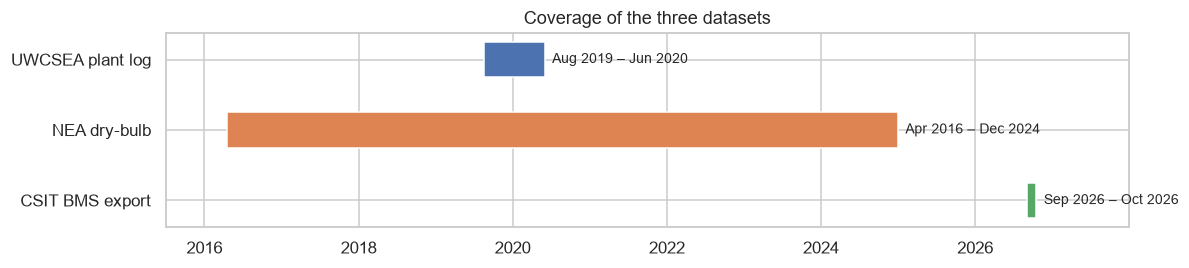

UWCSEA ∩ NEA: 288 days 13:00:00
CSIT ∩ NEA:   0 days 00:00:00


In [14]:
spans = {
    "UWCSEA plant log": (uwcsea_raw.index.min(), uwcsea_raw.index.max()),
    "NEA dry-bulb": (nea_raw.index.min(), nea_raw.index.max()),
    "CSIT BMS export": (csit_raw.dropna(how="all").index.min(), csit_raw.index.max()),
}
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (label, (a, b)) in enumerate(spans.items()):
    ax.barh(i, b - a, left=a, height=0.5, color=sns.color_palette()[i])
    ax.text(b, i, f"  {a:%b %Y} – {b:%b %Y}", va="center", fontsize=9)
ax.set_yticks(range(len(spans)), list(spans))
ax.invert_yaxis()
ax.set_xlim(pd.Timestamp("2015-07-01", tz=LOCAL_TZ), pd.Timestamp("2027-12-31", tz=LOCAL_TZ))
ax.set_title("Coverage of the three datasets")
plt.tight_layout()
plt.show()

overlap = lambda a, b: max(pd.Timedelta(0), min(a[1], b[1]) - max(a[0], b[0]))
print("UWCSEA ∩ NEA:", overlap(spans["UWCSEA plant log"], spans["NEA dry-bulb"]))
print("CSIT ∩ NEA:  ", overlap(spans["CSIT BMS export"], spans["NEA dry-bulb"]))

### 2.3 Columns

**UWCSEA**: ten columns, no categorical fields.

In [15]:
uw_cols = uwcsea_raw.describe().T
uw_cols.insert(0, "unit", pd.Series(UWCSEA_UNITS))
uw_cols.insert(1, "dtype", uwcsea_raw.dtypes.astype(str))
uw_cols.insert(2, "n_unique", uwcsea_raw.nunique())
uw_cols

,unit,dtype,n_unique,count,mean,std,min,25%,50%,75%,max
chw_flow_lps,L/s,float64,612,"13,615.000",96.741,12.559,72.400,86.900,94.200,106.100,141.500
cw_temp_c,°C,float64,83,"13,615.000",31.622,1.253,25.800,30.800,31.500,32.500,36.200
load_rt,RT,float64,3596,"13,615.000",520.940,96.336,55.100,443.500,495.600,595.000,"1,088.400"
chiller_kwh,kWh per interval,float64,1318,"13,615.000",126.812,30.160,18.000,105.600,118.100,138.300,281.200
oat_f,°F,int64,12,"13,615.000",83.104,3.842,73.000,81.000,82.000,86.000,93.000
dewpoint_f,°F,int64,12,"13,615.000",74.991,1.890,59.000,73.000,75.000,77.000,81.000
rh_pct,%,int64,26,"13,615.000",77.846,11.051,34.000,70.000,79.000,84.000,100.000
wind_mph,mph,int64,19,"13,615.000",6.307,3.742,0.000,3.000,6.000,9.000,21.000
pressure_inhg,inHg,float64,12,"13,615.000",29.808,0.051,29.620,29.770,29.800,29.830,29.950


**CSIT**: about 1,000 points, but most of them hold only a two-hour window on 15 Oct (`snapshot`) or nothing at all (`empty`). Only the `trend` class has history that models can be fitted on.

In [16]:
display(pd.crosstab(csit_columns["group"], csit_columns["class"], margins=True))
trend = csit_columns[csit_columns["class"] == "trend"]
snap = csit_columns[csit_columns["class"] == "snapshot"]
print(f"Snapshot window: {snap['first'].min()} to {snap['last'].max()}")
kind = trend.index.to_series().map(lambda t: "power kW" if re.search(r"\.(kW|kWatt|PMKWtotal)$", t)
                                   else "energy kWh" if t.endswith(".kWhr") else t.split(".")[-1])
print("Trend points by kind:", kind.value_counts().to_dict())
trend[~trend["group"].isin(["air side (AHU/FCU kW)", "building electrical"])]

class,empty,snapshot,trend,All
group,,,,
CHW pump,0,152,4,156
CW pump,14,143,4,161
air side (AHU/FCU kW),0,0,76,76
building electrical,0,0,112,112
chiller,0,210,3,213
cooling tower,0,242,4,246
headers and flow meters,0,28,0,28
plant summary,0,0,3,3
weather station,0,5,0,5


Snapshot window: 2026-10-15 19:38:00+08:00 to 2026-10-15 21:48:00+08:00
Trend points by kind: {'power kW': 194, 'energy kWh': 10, 'BldgLoad_Ton': 1, 'TotalEfficiency': 1}


,group,samples,first,last,class
CH.BldgLoad_Ton,plant summary,6312,2026-09-07 04:18:00+08:00,2026-10-15 21:48:00+08:00,trend
CH.TotalEfficiency,plant summary,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CH.PMKWtotal,plant summary,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CHWP.PMKWtotal,CHW pump,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CWP.PMKWtotal,CW pump,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CT.PMKWtotal,cooling tower,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CH1.kW,chiller,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CHWP1.kW,CHW pump,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CWP1.kWatt,CW pump,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend
CT1.kWatt,cooling tower,4686,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00,trend


The plant-side trend points are power meters plus the building load. Chilled-water and condenser-water temperatures, flows, the weather-station readings and the tower setpoints exist only in the snapshot. The air side has AHU and FCU **power** in the trend, but no AHU valve positions or supply-air temperatures anywhere in the export.

In [17]:
CSIT_TAGS = {
    "CH.BldgLoad_Ton": "load_rt", "CH.PMKWtotal": "chillers_kw", "CHWP.PMKWtotal": "chwp_kw",
    "CWP.PMKWtotal": "cwp_kw", "CT.PMKWtotal": "ct_kw", "CH.TotalEfficiency": "plant_kw_per_rt_bms",
    **{f"CH{i}.kW": f"ch{i}_kw" for i in (1, 2, 3)},
    **{f"CHWP{i}.kW": f"chwp{i}_kw" for i in (1, 2, 3)},
    **{f"CWP{i}.kWatt": f"cwp{i}_kw" for i in (1, 2, 3)},
    **{f"CT{i}.kWatt": f"ct{i}_kw" for i in (1, 2, 3)},
}
AHU_TAGS = [c for c in csit_raw.columns if ".AHU." in c and c.endswith(".kWatt")]
csit_key = csit_raw[list(CSIT_TAGS)].rename(columns=CSIT_TAGS)

CSIT_SNAPSHOT_TAGS = [
    "CHLR.DL_HDRCHWS_Temp_Sh", "CHLR.DL_HDRCHWR_Temp_Sh", "CHLR.DL_HDRCWS_Temp_Sh", "CHLR.DL_HDRCWR_Temp_Sh",
    "CHLR.DL_HDRCWR_TempSp", "CHLR.HdrChw_Qevap_kW", "CHLR.HdrCw_QCond_kW",
    "SIEMENS.CH_HDRCHWR_Flow", "SIEMENS.CH_HDRCWS_Flow",
    *[f"CH{i}.{p}" for i in (1, 2, 3) for p in ("CHWS_Temp", "CHWR_Temp", "CWS_Temp", "CWR_Temp", "CHW_Flow", "CW_Flow")],
    "OA_WetBulbT.Temp", "OA_WetBulbT.Rh", "OA_WetBulbT.WetBulb_Temp", "CT.AvgWBTemp", "CT.CalcWBTemp_Sh",
    "CT.CWS_TempSp", "CT.CWS_TempMinSp", "CT.CWS_TempMaxSp", "CT.CWTempSp_Constant_a", "CT.CWTempSp_Constant_b",
]
csit_snapshot = csit_raw[[c for c in CSIT_SNAPSHOT_TAGS if c in csit_raw.columns]].dropna(how="all")
print(f"{len(CSIT_TAGS)} plant trend tags, {len(AHU_TAGS)} AHU power tags, "
      f"{csit_snapshot.shape[1]} snapshot tags over {len(csit_snapshot)} minutes")

18 plant trend tags, 10 AHU power tags, 31 snapshot tags over 131 minutes


**NEA**: long format, one row per station per minute. Every row in all nine files is a 1-minute dry-bulb reading in °C; NEA publishes no humidity in this set, so wet-bulb cannot come from NEA alone.

In [18]:
display(nea_counts.groupby(["reading_type", "reading_unit"])["rows"].sum().to_frame("rows (all stations, all years)"))
network = nea_counts.pivot_table(index="station_id", columns="year", values="rows", aggfunc="sum")
print(f"{network.shape[0]} stations in the network; stations per year:", network.notna().sum().to_dict())
nea_catalogue.loc[NEA_SELECTED]

,,"rows (all stations, all years)"
reading_type,reading_unit,
DBT 1M F,deg C,66003046


21 stations in the network; stations per year: {2016: 21, 2017: 21, 2018: 17, 2019: 17, 2020: 17, 2021: 16, 2022: 16, 2023: 17, 2024: 17}


,station_name,lat,lon,first_year,last_year,km_to_UWCSEA,km_to_CSIT
station_id,,,,,,,
S111,Scotts Road,1.311,103.837,2016,2024,5.550,5.873
S116,West Coast Highway,1.281,103.754,2016,2024,4.521,3.871
S50,Clementi Road,1.334,103.777,2016,2024,3.394,4.763


### 2.4 Missing values
**UWCSEA**: no blank cells, but rows are missing from the 30-min grid. Reindexing to a full grid makes those gaps explicit.

In [19]:
uw_grid = pd.date_range(uwcsea_raw.index.min(), uwcsea_raw.index.max(), freq="30min", tz=LOCAL_TZ)
print("Blank cells in the file:", int(uwcsea_raw.isna().sum().sum()))
print(f"Rows on a full 30-min grid: {len(uw_grid):,}; present: {len(uwcsea_raw):,}; "
      f"missing: {len(uw_grid) - len(uwcsea_raw):,} ({1 - len(uwcsea_raw) / len(uw_grid):.2%})")
print("Zero values:", (uwcsea_raw == 0).sum()[lambda s: s > 0].to_dict())

Blank cells in the file: 0
Rows on a full 30-min grid: 13,851; present: 13,615; missing: 236 (1.70%)
Zero values: {'wind_mph': 12}


**CSIT**: coverage of each plant tag, measured over the whole export window and day by day. A value of 100 % means a reading every minute.

,samples,coverage_%_of_window,first,last
load_rt,6312,9.937,2026-09-07 04:18:00+08:00,2026-10-15 21:48:00+08:00
chillers_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
chwp_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
cwp_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
ct_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
plant_kw_per_rt_bms,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
ch1_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
ch2_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00
ch3_kw,24735,38.939,2026-09-07 16:19:00+08:00,2026-10-15 21:48:00+08:00
chwp1_kw,4686,7.377,2026-09-09 17:33:00+08:00,2026-10-15 21:48:00+08:00


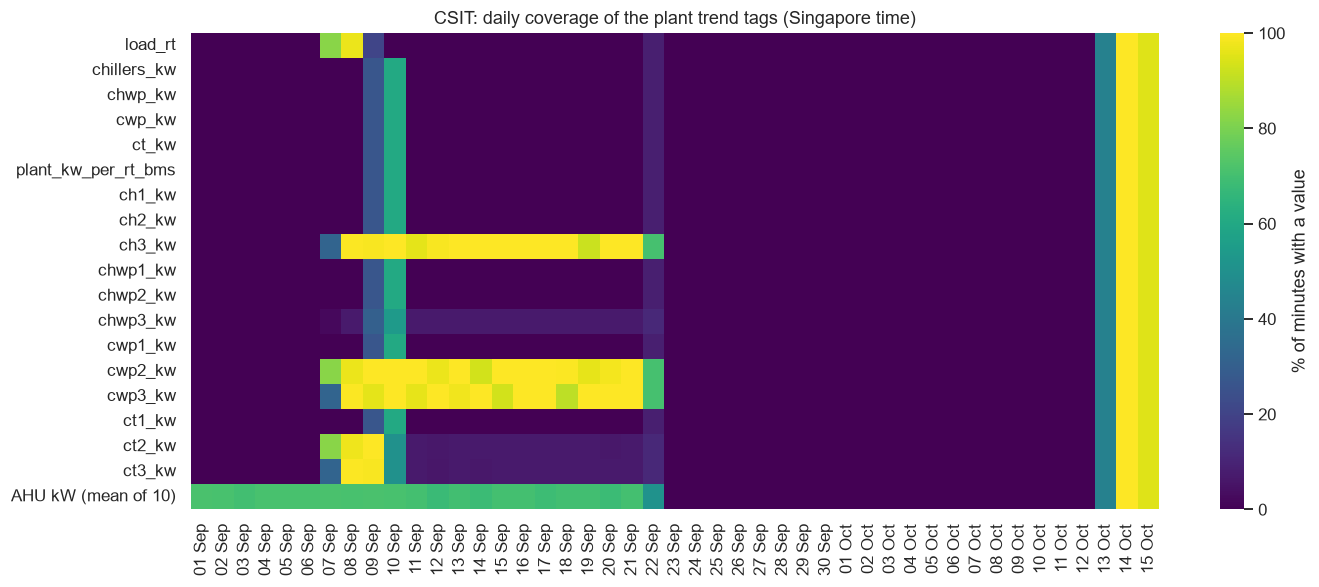

Days with any plant-power data: 6; equivalent full days: 3.3


In [20]:
window = csit_raw.index
csit_cov = pd.DataFrame({
    "samples": csit_key.notna().sum(),
    "coverage_%_of_window": 100 * csit_key.notna().mean(),
    "first": csit_key.apply(lambda s: s.first_valid_index()),
    "last": csit_key.apply(lambda s: s.last_valid_index()),
})
display(csit_cov)

daily = csit_key.notna().resample("D").mean().mul(100)
ahu_daily = csit_raw[AHU_TAGS].notna().resample("D").mean().mul(100).mean(axis=1).rename("AHU kW (mean of 10)")
fig, ax = plt.subplots(figsize=(13, 5.5))
sns.heatmap(pd.concat([daily, ahu_daily], axis=1).T, cmap="viridis", vmin=0, vmax=100,
            cbar_kws={"label": "% of minutes with a value"}, ax=ax,
            xticklabels=[d.strftime("%d %b") for d in daily.index])
ax.set_title("CSIT: daily coverage of the plant trend tags (Singapore time)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

plant_days = daily["chillers_kw"][daily["chillers_kw"] > 0]
print(f"Days with any plant-power data: {len(plant_days)}; "
      f"equivalent full days: {csit_key['chillers_kw'].notna().sum() / 1440:.1f}")

**NEA**: completeness of the selected stations by year (share of the minutes in the year with a reading).

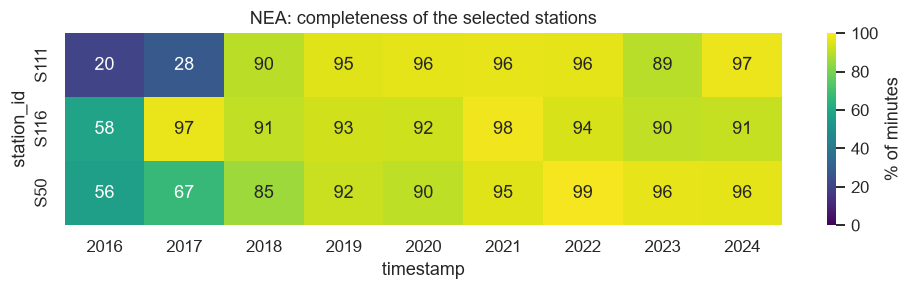

In [21]:
minutes_in_year = pd.Series({y: (pd.Timestamp(f"{y + 1}-01-01") - pd.Timestamp(f"{y}-01-01")) / pd.Timedelta("1min")
                             for y in NEA_YEARS})
nea_complete = nea_raw.notna().groupby(nea_raw.index.year).sum().div(minutes_in_year, axis=0).mul(100)
fig, ax = plt.subplots(figsize=(9, 2.8))
sns.heatmap(nea_complete.T, annot=True, fmt=".0f", cmap="viridis", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "% of minutes"})
ax.set_title("NEA: completeness of the selected stations")
plt.tight_layout()
plt.show()

### 2.5 Time intervals
Sampling regularity per dataset: the share of steps at the nominal interval, the number of gaps and the largest one.

In [22]:
def interval_stats(index, nominal):
    idx = pd.DatetimeIndex(index).sort_values()
    nominal = pd.Timedelta(nominal)
    d = idx.to_series().diff().dropna()
    gaps = d[d > nominal]
    return pd.Series({
        "samples": len(idx), "median_step": d.median(), "on_nominal_%": 100 * (d == nominal).mean(),
        "duplicates": int(idx.duplicated().sum()), "gaps": len(gaps),
        "missing_steps": int((gaps / nominal - 1).sum()),
        "largest_gap": gaps.max() if len(gaps) else pd.Timedelta(0),
    })


def gap_table(index, nominal, top=8):
    idx = pd.DatetimeIndex(index).sort_values()
    d = idx.to_series().diff()
    g = d[d > pd.Timedelta(nominal)].sort_values(ascending=False).head(top)
    return pd.DataFrame({"gap_after": [idx[idx.get_loc(t) - 1] for t in g.index], "resumes_at": g.index,
                         "duration": g.values}).reset_index(drop=True)


INTERVALS = pd.DataFrame({
    "UWCSEA": interval_stats(uwcsea_raw.index, "30min"),
    "CSIT load_rt": interval_stats(csit_key["load_rt"].dropna().index, "1min"),
    "CSIT chillers_kw": interval_stats(csit_key["chillers_kw"].dropna().index, "1min"),
    "CSIT ch3_kw": interval_stats(csit_key["ch3_kw"].dropna().index, "1min"),
    **{f"NEA {s}": interval_stats(nea_raw[s].dropna().index, "1min") for s in NEA_SELECTED},
}).T
INTERVALS

,samples,median_step,on_nominal_%,duplicates,gaps,missing_steps,largest_gap
UWCSEA,13615,0 days 00:30:00,99.736,0,36,236,0 days 09:00:00
CSIT load_rt,6312,0 days 00:01:00,98.827,0,74,49459,20 days 18:49:00
CSIT chillers_kw,4686,0 days 00:01:00,98.442,0,73,47410,20 days 18:49:00
CSIT ch3_kw,24735,0 days 00:01:00,99.693,0,76,30315,20 days 18:49:00
NEA S111,3716408,0 days 00:01:00,98.868,0,42085,865958,383 days 17:25:00
NEA S116,4229229,0 days 00:01:00,99.150,0,35931,353137,22 days 18:28:00
NEA S50,4083582,0 days 00:01:00,99.075,0,37791,498784,55 days 00:38:00


In [23]:
print("UWCSEA: largest gaps")
display(gap_table(uwcsea_raw.index, "30min"))
print("CSIT chillers_kw: largest gaps")
display(gap_table(csit_key["chillers_kw"].dropna().index, "1min", top=6))

UWCSEA: largest gaps


,gap_after,resumes_at,duration
0,2020-02-06 01:00:00+08:00,2020-02-06 10:00:00+08:00,0 days 09:00:00
1,2020-01-29 10:00:00+08:00,2020-01-29 19:00:00+08:00,0 days 09:00:00
2,2019-09-28 10:00:00+08:00,2019-09-28 17:30:00+08:00,0 days 07:30:00
3,2019-10-06 01:00:00+08:00,2019-10-06 08:30:00+08:00,0 days 07:30:00
4,2019-10-16 09:00:00+08:00,2019-10-16 16:30:00+08:00,0 days 07:30:00
5,2019-12-14 08:30:00+08:00,2019-12-14 15:30:00+08:00,0 days 07:00:00
6,2020-01-31 08:00:00+08:00,2020-01-31 15:00:00+08:00,0 days 07:00:00
7,2019-10-24 00:00:00+08:00,2019-10-24 07:00:00+08:00,0 days 07:00:00


CSIT chillers_kw: largest gaps


,gap_after,resumes_at,duration
0,2026-09-22 18:45:00+08:00,2026-10-13 13:34:00+08:00,20 days 18:49:00
1,2026-09-10 14:26:00+08:00,2026-09-22 15:20:00+08:00,12 days 00:54:00
2,2026-09-22 17:11:00+08:00,2026-09-22 17:56:00+08:00,0 days 00:45:00
3,2026-09-22 15:33:00+08:00,2026-09-22 16:09:00+08:00,0 days 00:36:00
4,2026-09-22 18:26:00+08:00,2026-09-22 18:29:00+08:00,0 days 00:03:00
5,2026-10-15 20:58:00+08:00,2026-10-15 21:00:00+08:00,0 days 00:02:00


### 2.6 Measurement quality
Each tag is checked for:

* **range**: outside physically plausible limits for this kind of plant;
* **negative**: negative readings on meters that cannot be negative;
* **stuck**: the same non-zero value repeated for longer than a sensor should hold still;
* **spike**: Hampel filter, more than *k* robust standard deviations from the rolling median;
* **resolution**: smallest step between distinct values, which shows quantisation.

Then each dataset gets physics and consistency checks that are specific to its tags.

In [24]:
def run_lengths(s):
    return s.groupby(s.ne(s.shift()).cumsum()).transform("size")


def stuck_mask(s, rule):
    """Runs of an unchanged value at least `min_run` samples long. `rule` is min_run or (min_run, idle_below):
    values with |v| <= idle_below are never flagged, since idle equipment can hold a constant standby reading."""
    min_run, idle_below = rule if isinstance(rule, tuple) else (rule, 0.0)
    return run_lengths(s).ge(min_run) & s.notna() & s.abs().gt(idle_below)


def hampel_mask(s, window, k=6.0, floor=0.0):
    mp = window // 2 + 1
    med = s.rolling(window, center=True, min_periods=mp).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=mp).median()
    scale = np.maximum(1.4826 * mad, floor)
    return (s - med).abs().gt(k * scale) & s.notna()


def resolution(s):
    d = np.diff(np.unique(s.dropna().to_numpy()))
    d = d[d > 1e-9]
    return d.min() if len(d) else np.nan


def quality_report(df, limits, stuck_runs=None, hampel=None):
    rows = []
    for c in df.columns:
        s = df[c]
        n = max(int(s.notna().sum()), 1)
        lo, hi = limits.get(c, (-np.inf, np.inf))
        row = {"tag": c, "valid": int(s.notna().sum()), "min": s.min(), "median": s.median(), "max": s.max(),
               "resolution": resolution(s), "negative_%": 100 * s.lt(0).sum() / n,
               "out_of_range_%": 100 * (s.lt(lo) | s.gt(hi)).sum() / n}
        if stuck_runs and c in stuck_runs:
            row["stuck_%"] = 100 * stuck_mask(s, stuck_runs[c]).sum() / n
        if hampel and c in hampel:
            row["spike_%"] = 100 * hampel_mask(s, *hampel[c]).sum() / n
        rows.append(row)
    return pd.DataFrame(rows).set_index("tag")

#### UWCSEA
Limits are set wide enough for a large chilled-water plant in Singapore. Weather values are excluded from the stuck test because the source reports whole °F and changes only every hour or so.

In [25]:
uw = uwcsea_raw.reindex(uw_grid)   # explicit gaps
UW_LIMITS_RAW = {"chw_flow_lps": (5, 400), "cw_temp_c": (20, 40), "load_rt": (10, 1500), "chiller_kwh": (1, 500),
                 "oat_f": (68, 104), "dewpoint_f": (59, 86), "rh_pct": (20, 100), "wind_mph": (0, 50),
                 "pressure_inhg": (29.0, 30.5)}
UW_STUCK = {c: 6 for c in ["chw_flow_lps", "cw_temp_c", "load_rt", "chiller_kwh"]}          # 3 hours
UW_HAMPEL = {"chw_flow_lps": (9, 6, 3.0), "cw_temp_c": (9, 6, 0.5), "load_rt": (9, 6, 20.0), "chiller_kwh": (9, 6, 5.0)}
quality_report(uw, UW_LIMITS_RAW, UW_STUCK, UW_HAMPEL)

,valid,min,median,max,resolution,negative_%,out_of_range_%,stuck_%,spike_%
tag,,,,,,,,,
chw_flow_lps,13615,72.400,94.200,141.500,0.100,0.000,0.000,1.748,0.375
cw_temp_c,13615,25.800,31.500,36.200,0.100,0.000,0.000,2.115,0.015
load_rt,13615,55.100,495.600,"1,088.400",0.100,0.000,0.000,1.748,0.426
chiller_kwh,13615,18.000,118.100,281.200,0.100,0.000,0.000,0.382,1.124
oat_f,13615,73.000,82.000,93.000,1.000,0.000,0.000,NaN,NaN
dewpoint_f,13615,59.000,75.000,81.000,1.000,0.000,0.000,NaN,NaN
rh_pct,13615,34.000,79.000,100.000,1.000,0.000,0.000,NaN,NaN
wind_mph,13615,0.000,6.000,21.000,1.000,0.000,0.000,NaN,NaN
pressure_inhg,13615,29.620,29.800,29.950,0.030,0.000,0.000,NaN,NaN


In [26]:
uw_chk = pd.DataFrame(index=uw.index)
uw_chk["load_kwth"] = rt_to_kw(uw["load_rt"])
uw_chk["chiller_kw"] = uw["chiller_kwh"] / 0.5                 # kWh per 30-min interval -> mean kW
uw_chk["kw_per_rt"] = uw_chk["chiller_kw"] / uw["load_rt"]
uw_chk["chw_dt_implied_c"] = implied_delta_t(uw_chk["load_kwth"], uw["chw_flow_lps"])
uw_chk["oat_c"] = f_to_c(uw["oat_f"])
uw_chk["dewpoint_c"] = f_to_c(uw["dewpoint_f"])
uw_chk["rh_from_t_td"] = rh_from_t_td(uw_chk["oat_c"], uw_chk["dewpoint_c"])
uw_chk["wetbulb_c"] = wet_bulb_stull(uw_chk["oat_c"], uw["rh_pct"])
uw_chk["cw_minus_wb_c"] = uw["cw_temp_c"] - uw_chk["wetbulb_c"]

UW_CONSISTENCY = pd.DataFrame([
    ("Chiller kW/RT (kWh/0.5 h ÷ RT)", "0.35 - 1.0", uw_chk["kw_per_rt"].median(),
     100 * (~uw_chk["kw_per_rt"].between(0.35, 1.0) & uw_chk["kw_per_rt"].notna()).mean()),
    ("Implied CHW ΔT from load and flow (K)", "2 - 9", uw_chk["chw_dt_implied_c"].median(),
     100 * (~uw_chk["chw_dt_implied_c"].between(2, 9) & uw_chk["chw_dt_implied_c"].notna()).mean()),
    ("RH reported − RH from T and dew point (%)", "|Δ| ≤ 5", (uw["rh_pct"] - uw_chk["rh_from_t_td"]).median(),
     100 * ((uw["rh_pct"] - uw_chk["rh_from_t_td"]).abs() > 5).mean()),
    ("Cooling water − wet-bulb (K)", "> 0 (tower approach)", uw_chk["cw_minus_wb_c"].median(),
     100 * (uw_chk["cw_minus_wb_c"] <= 0).mean()),
], columns=["check", "expected", "median", "% rows failing"])
display(UW_CONSISTENCY)
print("Weather resolution: outside temperature in whole °F =", round(5 / 9, 2), "°C steps; "
      f"{100 * uw['oat_f'].eq(uw['oat_f'].shift()).mean():.0f} % of steps repeat the previous value")

,check,expected,median,% rows failing
0,Chiller kW/RT (kWh/0.5 h ÷ RT),0.35 - 1.0,0.478,0.116
1,Implied CHW ΔT from load and flow (K),2 - 9,4.459,0.029
2,RH reported − RH from T and dew point (%),|Δ| ≤ 5,0.384,0.000
3,Cooling water − wet-bulb (K),> 0 (tower approach),6.349,0.000


Weather resolution: outside temperature in whole °F = 0.56 °C steps; 68 % of steps repeat the previous value


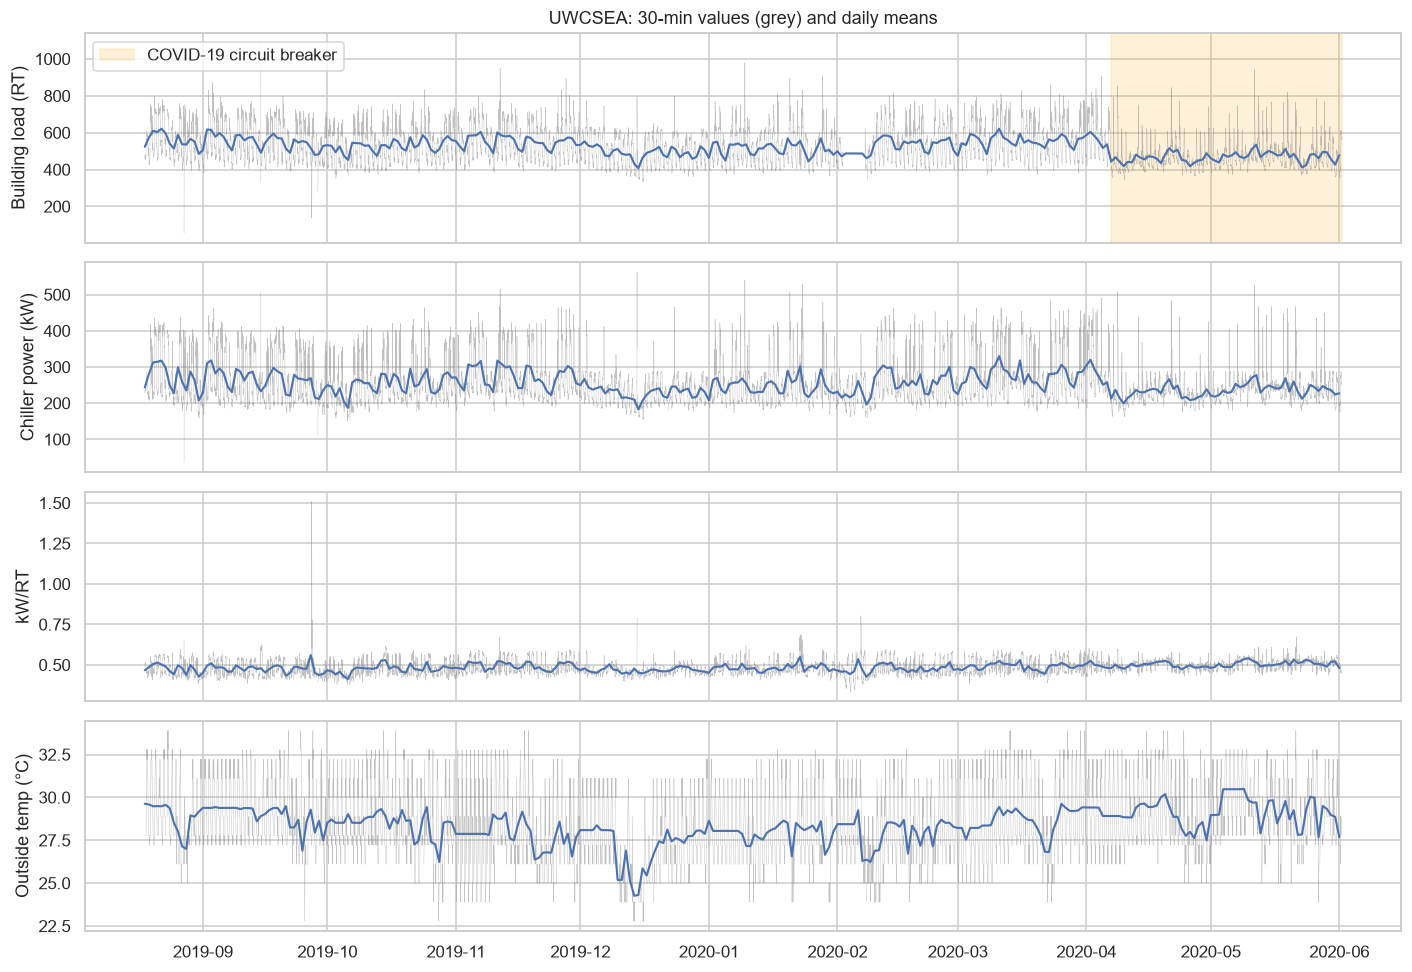

In [27]:
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
daily_uw = pd.concat([uw[["load_rt"]], uw_chk[["chiller_kw", "kw_per_rt", "oat_c"]]], axis=1)
for ax, (col, label) in zip(axes, [("load_rt", "Building load (RT)"), ("chiller_kw", "Chiller power (kW)"),
                                   ("kw_per_rt", "kW/RT"), ("oat_c", "Outside temp (°C)")]):
    ax.plot(daily_uw.index, daily_uw[col], lw=0.3, alpha=0.5, color="grey")
    ax.plot(daily_uw[col].resample("D").mean(), lw=1.4)
    ax.set_ylabel(label)
axes[0].axvspan(pd.Timestamp("2020-04-07", tz=LOCAL_TZ), uw.index.max(), color="orange", alpha=0.15,
                label="COVID-19 circuit breaker")
axes[0].legend(loc="upper left")
axes[0].set_title("UWCSEA: 30-min values (grey) and daily means")
plt.tight_layout()
plt.show()

#### CSIT
Power meters are checked for negative and out-of-range values, and the BMS totals are checked against the sum of the individual meters. The snapshot is used to check the sensors the reset rules depend on.

In [28]:
CSIT_LIMITS = {"load_rt": (0, 1000), "chillers_kw": (0, 700), "chwp_kw": (0, 60), "cwp_kw": (0, 75), "ct_kw": (0, 45),
               "plant_kw_per_rt_bms": (0, 2.5),
               **{f"ch{i}_kw": (0, 250) for i in (1, 2, 3)}, **{f"chwp{i}_kw": (0, 20) for i in (1, 2, 3)},
               **{f"cwp{i}_kw": (0, 25) for i in (1, 2, 3)}, **{f"ct{i}_kw": (0, 15) for i in (1, 2, 3)}}
# 30 min unchanged while running; below the idle level a constant standby reading is normal
CSIT_IDLE = {"load_rt": 10.0, "chillers_kw": 5.0, "ch1_kw": 5.0, "ch2_kw": 5.0, "ch3_kw": 5.0}
CSIT_STUCK = {c: (30, CSIT_IDLE.get(c, 1.0 if c.startswith("ct") else 0.5))
              for c in CSIT_TAGS.values() if c != "plant_kw_per_rt_bms"}
CSIT_HAMPEL = {c: (15, 8, 10.0 if c == "load_rt" else 0.5 if c.startswith(("ct", "chwp")) else 2.0)
               for c in CSIT_TAGS.values() if c != "plant_kw_per_rt_bms"}
quality_report(csit_key, CSIT_LIMITS, CSIT_STUCK, CSIT_HAMPEL)

,valid,min,median,max,resolution,negative_%,out_of_range_%,stuck_%,spike_%
tag,,,,,,,,,
load_rt,6312,-57.938,86.754,490.266,0.000,0.111,0.111,0.000,0.032
chillers_kw,4686,-32.610,42.349,248.827,0.000,1.302,1.302,0.000,1.003
chwp_kw,4686,"-6,243.631",4.004,"15,531.610",0.000,13.615,14.255,0.000,0.363
cwp_kw,4686,-8.935,5.419,20.791,0.000,0.235,0.235,0.000,0.000
ct_kw,4686,0.000,0.855,5.648,0.000,0.000,0.000,0.000,0.000
plant_kw_per_rt_bms,4686,-38.638,0.520,454.896,0.000,0.320,26.867,NaN,NaN
ch1_kw,4686,0.000,41.141,151.743,0.000,0.000,0.000,0.000,0.491
ch2_kw,4686,0.000,0.367,130.245,0.000,0.000,0.000,26.654,0.811
ch3_kw,24735,0.000,0.061,102.558,0.000,0.000,0.000,0.000,0.101


In [29]:
k = csit_key
running = k["load_rt"] > 30
plant_kw_sum = k[["chillers_kw", "chwp_kw", "cwp_kw", "ct_kw"]].sum(axis=1, min_count=4)


def agreement(name, a, b, tol):
    d = (a - b).dropna()
    return {"check": name, "rows": len(d), "median_abs_diff": d.abs().median(), "% rows |diff| > tol": 100 * (d.abs() > tol).mean(),
            "tol": tol}


CSIT_CONSISTENCY = pd.DataFrame([
    agreement("CH.PMKWtotal = CH1+CH2+CH3 kW", k["chillers_kw"], k[["ch1_kw", "ch2_kw", "ch3_kw"]].sum(axis=1, min_count=3), 2.0),
    agreement("CHWP.PMKWtotal = sum of CHW pumps", k["chwp_kw"], k[["chwp1_kw", "chwp2_kw", "chwp3_kw"]].sum(axis=1, min_count=3), 0.5),
    agreement("CWP.PMKWtotal = sum of CW pumps", k["cwp_kw"], k[["cwp1_kw", "cwp2_kw", "cwp3_kw"]].sum(axis=1, min_count=3), 0.5),
    agreement("CT.PMKWtotal = sum of tower cells", k["ct_kw"], k[["ct1_kw", "ct2_kw", "ct3_kw"]].sum(axis=1, min_count=3), 0.5),
    agreement("CH.TotalEfficiency = plant kW / load (load > 30 RT)", k["plant_kw_per_rt_bms"][running],
              (plant_kw_sum / k["load_rt"])[running], 0.02),
]).set_index("check")
CSIT_CONSISTENCY

,rows,median_abs_diff,% rows |diff| > tol,tol
check,,,,
CH.PMKWtotal = CH1+CH2+CH3 kW,4656,0.746,29.016,2.000
CHWP.PMKWtotal = sum of CHW pumps,4513,0.004,26.346,0.500
CWP.PMKWtotal = sum of CW pumps,4656,0.025,2.749,0.500
CT.PMKWtotal = sum of tower cells,4476,0.067,4.111,0.500
CH.TotalEfficiency = plant kW / load (load > 30 RT),3407,0.000,4.579,0.020


In [30]:
snap_stats = csit_snapshot.agg(["count", "min", "median", "max"]).T
display(snap_stats)

hdr_q = csit_snapshot["CHLR.HdrChw_Qevap_kW"]
bms_q = rt_to_kw(csit_key.loc[hdr_q.dropna().index, "load_rt"])
DOC_VS_BMS = pd.DataFrame([
    ("Chilled water supply setpoint", f"fixed at {PLANT['chws_setpoint_today_c']} °C",
     f"header CHWS median {csit_snapshot['CHLR.DL_HDRCHWS_Temp_Sh'].median():.1f} °C"),
    ("Tower setpoint formula", "0.5 × wet-bulb + 27",
     f"a = {csit_snapshot['CT.CWTempSp_Constant_a'].median():g}, b = {csit_snapshot['CT.CWTempSp_Constant_b'].median():g}"),
    ("Tower setpoint limits", "23 to 29.5 °C",
     f"{csit_snapshot['CT.CWS_TempMinSp'].median():g} to {csit_snapshot['CT.CWS_TempMaxSp'].median():g} °C"),
    ("Tower setpoint in use", "29.5 °C in practice", f"{csit_snapshot['CT.CWS_TempSp'].median():g} °C"),
    ("Weather station at the towers", "dry-bulb, RH, wet-bulb every minute",
     f"Temp {csit_snapshot['OA_WetBulbT.Temp'].median():g}, RH {csit_snapshot['OA_WetBulbT.Rh'].median():g}, "
     f"WB {csit_snapshot['OA_WetBulbT.WetBulb_Temp'].median():g}"),
    ("Header heat balance", "BMS load agrees with header Q within ±5 %",
     f"median Qevap / (load × 3.517) = {(hdr_q.dropna() / bms_q).median():.2f}"),
], columns=["item", "AI/ML Document", "CSIT snapshot, 15 Oct 2026"])
DOC_VS_BMS

,count,min,median,max
CHLR.DL_HDRCHWS_Temp_Sh,66.000,9.594,9.727,9.885
CHLR.DL_HDRCHWR_Temp_Sh,66.000,12.403,12.634,12.957
CHLR.DL_HDRCWS_Temp_Sh,66.000,27.799,28.784,28.939
CHLR.DL_HDRCWR_Temp_Sh,66.000,30.023,31.188,31.457
CHLR.DL_HDRCWR_TempSp,66.000,35.000,35.000,35.000
CHLR.HdrChw_Qevap_kW,66.000,384.371,430.147,991.120
CHLR.HdrCw_QCond_kW,66.000,359.420,406.505,978.460
SIEMENS.CH_HDRCHWR_Flow,66.000,0.000,0.000,0.000
SIEMENS.CH_HDRCWS_Flow,66.000,0.000,0.000,0.000
CH1.CHWS_Temp,65.000,9.600,9.718,17.506


,item,AI/ML Document,"CSIT snapshot, 15 Oct 2026"
0,Chilled water supply setpoint,fixed at 10.0 °C,header CHWS median 9.7 °C
1,Tower setpoint formula,0.5 × wet-bulb + 27,"a = 0.5, b = 15.5"
2,Tower setpoint limits,23 to 29.5 °C,26 to 29.5 °C
3,Tower setpoint in use,29.5 °C in practice,29.5 °C
4,Weather station at the towers,"dry-bulb, RH, wet-bulb every minute","Temp 0, RH 2.4, WB -5.8654"
5,Header heat balance,BMS load agrees with header Q within ±5 %,median Qevap / (load × 3.517) = 1.13


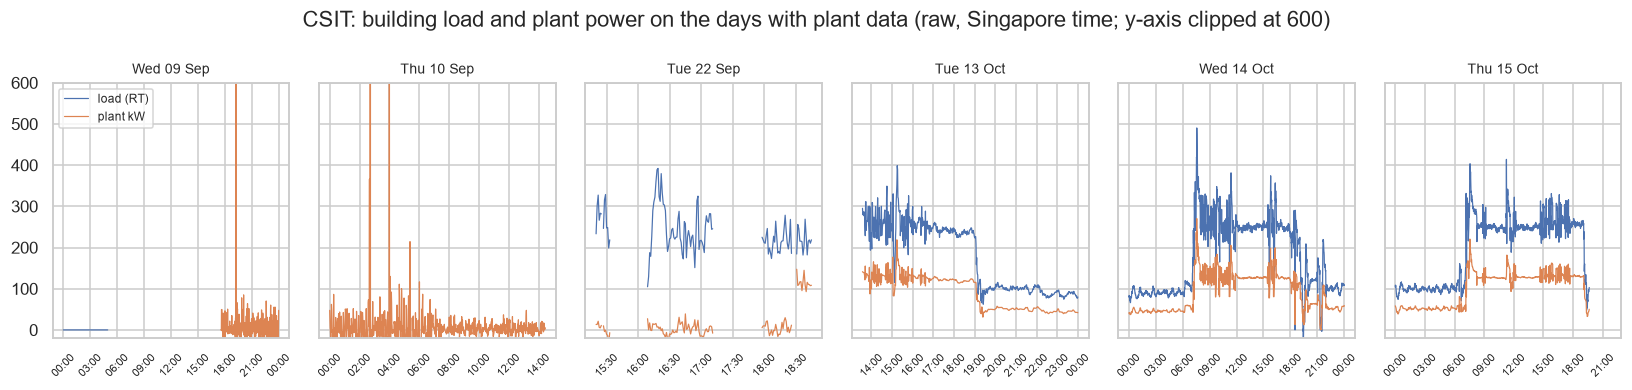

In [31]:
plant_days_idx = csit_key["chillers_kw"].dropna().index.normalize().unique()
fig, axes = plt.subplots(1, len(plant_days_idx), figsize=(15, 3.6), sharey=True)
for ax, day in zip(np.atleast_1d(axes), plant_days_idx):
    d = csit_key.loc[day: day + pd.Timedelta("1D")]
    ax.plot(d.index, d["load_rt"], lw=0.8, label="load (RT)")
    ax.plot(d.index, plant_kw_sum.loc[d.index], lw=0.8, label="plant kW")
    ax.set_title(day.strftime("%a %d %b"), fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=LOCAL_TZ))
    ax.tick_params(axis="x", labelsize=7, rotation=45)
np.atleast_1d(axes)[0].legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylim(-20, 600)   # meter spikes reach ±15,000 kW; see the quality table above
fig.suptitle("CSIT: building load and plant power on the days with plant data (raw, Singapore time; y-axis clipped at 600)")
plt.tight_layout()
plt.show()

#### NEA
Per-station quality on the 1-min readings, then agreement between neighbouring stations: each station against the mean of the other selected stations, at 15-min resolution.

In [32]:
NEA_LIMITS = {s: (18, 40) for s in NEA_SELECTED}
NEA_STUCK = {s: 120 for s in NEA_SELECTED}                 # 2 hours unchanged at 0.1 °C resolution
NEA_HAMPEL = {s: (31, 8, 0.3) for s in NEA_SELECTED}
nea_full = nea_raw.reindex(pd.date_range(nea_raw.index.min(), nea_raw.index.max(), freq="1min", tz=LOCAL_TZ))
display(quality_report(nea_full, NEA_LIMITS, NEA_STUCK, NEA_HAMPEL))

nea_15 = nea_full.resample("15min").mean()
rows = []
for s in NEA_SELECTED:
    others = nea_15.drop(columns=s).mean(axis=1)
    d = (nea_15[s] - others).dropna()
    rows.append({"station": s, "name": nea_catalogue.loc[s, "station_name"], "bias_°C": d.mean(),
                 "rmse_°C": np.sqrt((d ** 2).mean()), "|diff| > 2 °C %": 100 * (d.abs() > 2).mean()})
pd.DataFrame(rows).set_index("station")

,valid,min,median,max,resolution,negative_%,out_of_range_%,stuck_%,spike_%
tag,,,,,,,,,
S111,3716408,21.000,27.600,35.800,0.100,0.000,0.000,0.136,0.000
S116,4229229,21.100,28.400,34.800,0.100,0.000,0.000,0.025,0.000
S50,4083582,21.100,27.600,36.000,0.100,0.000,0.000,0.021,0.000


,name,bias_°C,rmse_°C,|diff| > 2 °C %
station,,,,
S111,Scotts Road,-0.354,0.657,0.930
S116,West Coast Highway,0.585,0.973,2.125
S50,Clementi Road,-0.264,0.775,1.655


### 2.7 Findings from the analysis

**UWCSEA: clean plant-level history, about ten months**
* 13,615 rows at 30 min, 18 Aug 2019 to 1 Jun 2020. No blank cells; 236 slots (1.7 %) are missing from the grid in 36 gaps, the longest 9 h.
* Units are mixed: weather in whole °F, mph and inHg, chiller energy in kWh per 30-min interval. Read that way the median efficiency is **0.48 kW/RT** and the implied chilled-water ΔT is **4.5 K**; fewer than 0.2 % of rows fall outside plausible ranges. RH agrees with temperature and dew point.
* The weather column is coarse: steps of 0.56 °C, and 68 % of steps repeat the previous value. It also trails the NEA stations by about 30 min (3.3). NEA dry-bulb replaces it.
* About 1.7 % of plant values hold an identical reading for 3 h or more (logger hold), and about 0.4 to 1.1 % are spikes, including the 1,088 RT maximum.
* Load drops by about 16 % from 7 Apr 2020 (COVID-19 circuit breaker). This is a regime change, handled in 3.5.
* The data are **plant-level only**: no CHWS/CHWR temperatures, condenser flow, per-chiller power, or pump and tower power. They support the demand forecast and a plant-level baseline, not per-chiller curves.

**NEA: reliable and complete, dry-bulb only**
* 66 million readings from 21 stations, all 1-min dry-bulb in °C. There is **no humidity**, so wet-bulb cannot come from NEA.
* Stations used: S116 West Coast Hwy (3.9 km from CSIT), S50 Clementi Rd, S111 Scotts Rd. Completeness is 91 to 99 % per year, except S111 in 2016 and 2017 and S50 in 2017.
* 8 % of readings are stamped at hh:mm:59. They are rounded to the minute on load.
* No out-of-range values, under 0.2 % stuck, negligible spikes. The stations agree within 0.7 to 1.0 °C RMSE at 15 min; the coastal S116 runs about 0.6 °C warm.
* NEA ends in Dec 2024. It covers the UWCSEA period fully and **does not overlap CSIT at all**.

**CSIT: the target plant, and the main constraint on this project**
* About 1,000 points, but 780 hold only a **131-minute snapshot** (15 Oct, 19:38 to 21:48) and 14 are empty. The 206 points with history are power meters, the building load, and AHU, FCU and electrical kW.
* Plant power covers **4,686 minutes, about 3.3 days**, spread over six calendar days (9 to 10 Sep, 22 Sep, 13 to 15 Oct) with gaps of 12 and 21 days. The document's rule of keeping the most recent **two weeks as test days cannot be met**.
* The trend has no CHWS/CHWR/CWS/CWR temperatures, flows, setpoints or tower fan speeds. So the **chiller performance curve, tower model and pump curves in Section 7 cannot be fitted from this export**. Only the demand forecast and a plant-kW baseline can be prototyped.
* The export has **no AHU valve positions or supply-air temperatures**, which the chilled-water reset rule (Section 4) depends on.
* Meter faults:
  * the CHW pump total reads from −6,244 to 15,532 kW, with 14 % of values out of range;
  * CHWP3 is 63 % out of range, and the CT2 and CT3 cells are 16 to 18 % out of range (spikes to 113 and 1,051 kW);
  * the BMS chiller total differs from CH1 + CH2 + CH3 by more than 2 kW in 29 % of rows.
  * `CH.TotalEfficiency` is confirmed as plant kW ÷ load, and is meaningless at low load (up to 455).
* Sensor faults in the snapshot:
  * the tower weather station reads 0 °C, 2.4 % RH and −5.9 °C wet-bulb;
  * `CT.AvgWBTemp` is fixed at 23 °C;
  * the header flow meters read 0;
  * header Q<sub>evap</sub> is 13 % above the BMS load, so the ±5 % heat-balance check in Section 8 would block every recommendation.
* The BMS differs from the document: the tower formula constant is **b = 15.5** (document: 27), the minimum tower setpoint is **26 °C** (document: 23 °C), and the CHWS header reads 9.7 °C (document: 10.0 °C). The tower setpoint in use is 29.5 °C, as the document says.

**What this means for the models**

| Section 7 model | Can be trained now | Data |
|---|---|---|
| Cooling demand forecast | yes | UWCSEA (main), CSIT (transfer smoke test) |
| Weather forecast | dry-bulb only | NEA 2016 to 2024; humidity and wet-bulb need the CSIT weather station repaired |
| Chiller performance curve | no | needs CSIT CHWS, CWS and load per chiller in the trend |
| Cooling tower model | no | needs CSIT tower temperatures, fan speed and wet-bulb |
| Pump and fan curves | partly | CSIT pump and fan kW exist; speed and flow are missing |
| Baseline | prototype | UWCSEA plant kW; CSIT has only about 3 days |

**Requests to the BMS contractor:**
1. A continuous 1-min export of the Section 6 point list for at least eight weeks.
2. Repair of the tower weather station and the header flow meters.
3. Confirmation of the tower formula constants and limits.

## 3. Data Preprocessing

### 3.1 Unit conversion
* **UWCSEA**: °F to °C, mph to m/s, inHg to kPa, RT to kW thermal. Chiller energy is logged in kWh per 30-min interval and converted to mean kW (× 2). That reading gives a median of about 0.5 kW/RT (Part 2), which fits a chiller plant; taking the column as kW would give about 0.25 kW/RT, which is not credible.
* **CSIT**: RT to kW thermal; timestamps are already converted from UTC to Singapore time. The hourly load profile below confirms the conversion: load rises in the local morning and peaks in the afternoon.
* **NEA**: already °C, timestamps already Singapore time (`+08:00`).

In [33]:
def uwcsea_to_si(raw):
    out = pd.DataFrame(index=raw.index)
    out["chw_flow_lps"] = raw["chw_flow_lps"]
    out["cw_temp_c"] = raw["cw_temp_c"]
    out["load_rt"] = raw["load_rt"]
    out["chiller_kw"] = raw["chiller_kwh"] / 0.5
    out["oat_c"] = f_to_c(raw["oat_f"])
    out["dewpoint_c"] = f_to_c(raw["dewpoint_f"])
    out["rh_pct"] = raw["rh_pct"]
    out["wind_ms"] = mph_to_ms(raw["wind_mph"])
    out["pressure_kpa"] = inhg_to_kpa(raw["pressure_inhg"])
    return out


uw_si = uwcsea_to_si(uw)   # uw = raw values on the full 30-min grid
uw_si.describe().T[["mean", "min", "max"]]

,mean,min,max
chw_flow_lps,96.741,72.400,141.500
cw_temp_c,31.622,25.800,36.200
load_rt,520.940,55.100,"1,088.400"
chiller_kw,253.623,36.000,562.400
oat_c,28.391,22.778,33.889
dewpoint_c,23.884,15.000,27.222
rh_pct,77.846,34.000,100.000
wind_ms,2.819,0.000,9.388
pressure_kpa,100.942,100.305,101.422


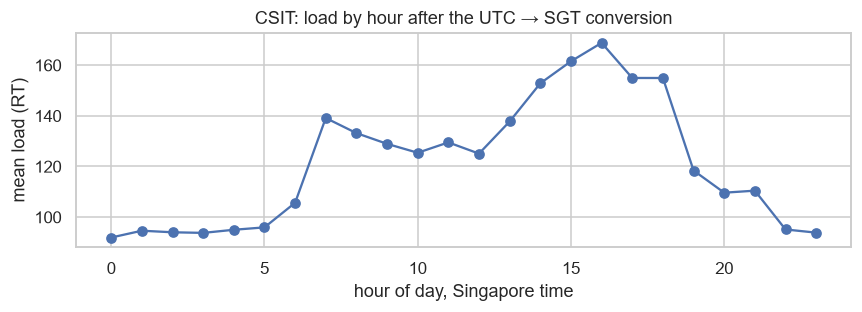

In [34]:
hourly = csit_key["load_rt"].where(csit_key["load_rt"] > 0).groupby(csit_key.index.hour).mean()
fig, ax = plt.subplots(figsize=(8, 3))
hourly.plot(ax=ax, marker="o")
ax.set_xlabel("hour of day, Singapore time")
ax.set_ylabel("mean load (RT)")
ax.set_title("CSIT: load by hour after the UTC → SGT conversion")
plt.tight_layout()
plt.show()

### 3.2 Cleaning
Rules run in order on every tag, and each removed value is counted once under the first rule that caught it:

1. **meter noise**: small negative readings on power and load meters (≥ −1 kW, ≥ −5 RT) are set to 0, because the equipment is off;
2. **range**: values outside the Part 2 limits are removed;
3. **stuck**: runs of an unchanged non-zero value longer than the tag's limit are removed;
4. **spike**: Hampel outliers are removed;
5. **short gaps**: gaps up to a tag-specific length are filled by time interpolation. Longer gaps stay missing. This replaces the original forward/back fill, which copied stale values across days.

The CSIT short-gap limit is 5 minutes, the staleness limit in document Section 8.

In [35]:
def interpolate_short_gaps(s, max_gap):
    """Interpolate only gaps of at most max_gap consecutive missing samples (inside the series)."""
    if not max_gap:
        return s
    isna = s.isna()
    run = isna.groupby(isna.ne(isna.shift()).cumsum()).transform("size")
    filled = s.interpolate(method="time", limit_area="inside")
    return s.where(~(isna & run.le(max_gap)), filled)


def clean_frame(df, limits, *, zero_tol=None, stuck_runs=None, hampel=None, max_gap=0):
    out, log = df.copy(), []
    for c in out.columns:
        s = out[c].copy()
        entry = {"tag": c, "valid_raw": int(s.notna().sum())}
        if zero_tol and c in zero_tol:
            m = s.ge(-zero_tol[c]) & s.lt(0)
            entry["noise_to_zero"] = int(m.sum())
            s[m] = 0.0
        lo, hi = limits.get(c, (-np.inf, np.inf))
        m = s.lt(lo) | s.gt(hi)
        entry["out_of_range"] = int(m.sum())
        s[m] = np.nan
        if stuck_runs and c in stuck_runs:
            m = stuck_mask(s, stuck_runs[c])
            entry["stuck"] = int(m.sum())
            s[m] = np.nan
        if hampel and c in hampel:
            m = hampel_mask(s, *hampel[c])
            entry["spike"] = int(m.sum())
            s[m] = np.nan
        before = int(s.notna().sum())
        s = interpolate_short_gaps(s, max_gap)
        entry["interpolated"] = int(s.notna().sum()) - before
        entry["valid_clean"] = int(s.notna().sum())
        out[c] = s
        log.append(entry)
    return out, pd.DataFrame(log).set_index("tag").fillna(0).astype(int)

In [36]:
UW_LIMITS = {"chw_flow_lps": (5, 400), "cw_temp_c": (20, 40), "load_rt": (10, 1500), "chiller_kw": (2, 1000),
             "oat_c": (20, 40), "dewpoint_c": (15, 30), "rh_pct": (20, 100), "wind_ms": (0, 25), "pressure_kpa": (98, 104)}
UW_HAMPEL_SI = {"chw_flow_lps": (9, 6, 3.0), "cw_temp_c": (9, 6, 0.5), "load_rt": (9, 6, 20.0), "chiller_kw": (9, 6, 10.0)}
uw_clean, uw_log = clean_frame(uw_si, UW_LIMITS, stuck_runs=UW_STUCK | {"chiller_kw": 6}, hampel=UW_HAMPEL_SI, max_gap=2)
print("UWCSEA cleaning log (counts of 30-min values)")
uw_log

UWCSEA cleaning log (counts of 30-min values)


,valid_raw,out_of_range,stuck,spike,interpolated,valid_clean
tag,,,,,,
chw_flow_lps,13615,0,238,51,58,13384
cw_temp_c,13615,0,288,2,13,13338
load_rt,13615,0,238,58,66,13385
chiller_kw,13615,0,52,149,151,13565
oat_c,13615,0,0,0,11,13626
dewpoint_c,13615,0,0,0,11,13626
rh_pct,13615,0,0,0,11,13626
wind_ms,13615,0,0,0,11,13626
pressure_kpa,13615,0,0,0,11,13626


In [37]:
CSIT_ZERO_TOL = {c: (5.0 if c == "load_rt" else 1.0) for c in CSIT_TAGS.values() if c != "plant_kw_per_rt_bms"}
csit_1min, csit_log = clean_frame(csit_key.drop(columns="plant_kw_per_rt_bms"), CSIT_LIMITS, zero_tol=CSIT_ZERO_TOL,
                                  stuck_runs=CSIT_STUCK, hampel=CSIT_HAMPEL, max_gap=5)

# AHU power: the tags with near-complete history, cleaned the same way, summed as an air-side activity signal
ahu_cov = csit_raw[AHU_TAGS].notna().mean()
AHU_KEEP = ahu_cov[ahu_cov >= 0.5 * ahu_cov.max()].index.tolist()
ahu_clean, ahu_log = clean_frame(csit_raw[AHU_KEEP], {c: (0, 60) for c in AHU_KEEP},
                                 zero_tol={c: 0.5 for c in AHU_KEEP}, max_gap=5)
csit_1min["ahu_kw_total"] = ahu_clean.sum(axis=1, min_count=len(AHU_KEEP))
print(f"AHU tags used: {len(AHU_KEEP)} of {len(AHU_TAGS)}")
print("CSIT cleaning log (counts of 1-min values)")
pd.concat([csit_log, ahu_log.sum().rename("AHU tags (sum)").to_frame().T])

AHU tags used: 7 of 10
CSIT cleaning log (counts of 1-min values)


,valid_raw,noise_to_zero,out_of_range,stuck,spike,interpolated,valid_clean
load_rt,6312,5,2,0.000,2.000,74,6382
chillers_kw,4686,8,53,0.000,47.000,145,4731
chwp_kw,4686,48,620,0.000,8.000,560,4618
cwp_kw,4686,9,2,0.000,0.000,72,4756
ct_kw,4686,0,0,0.000,0.000,70,4756
ch1_kw,4686,0,0,0.000,23.000,93,4756
ch2_kw,4686,0,0,"1,249.000",36.000,106,3507
ch3_kw,24735,0,0,0.000,25.000,97,24807
chwp1_kw,4686,0,0,0.000,0.000,70,4756
chwp2_kw,4686,11,0,0.000,0.000,70,4756


In [38]:
nea_clean, nea_log = clean_frame(nea_full, NEA_LIMITS, stuck_runs=NEA_STUCK, hampel=NEA_HAMPEL, max_gap=5)
print("NEA cleaning log (counts of 1-min values)")
nea_log

NEA cleaning log (counts of 1-min values)


,valid_raw,out_of_range,stuck,spike,interpolated,valid_clean
tag,,,,,,
S111,3716408,0,5059,6,50410,3761753
S116,4229229,0,1076,4,42635,4270784
S50,4083582,0,841,6,55183,4137918


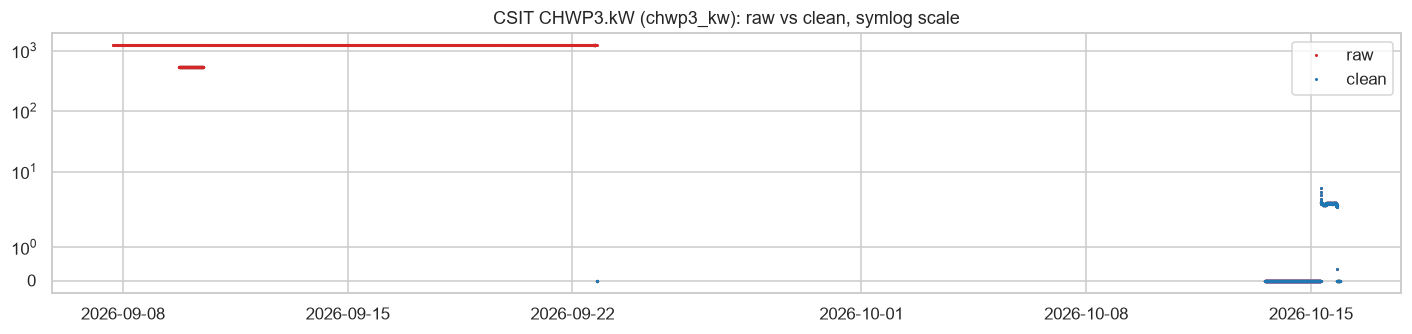

In [39]:
# Before / after on the CSIT tag with the most removed values
worst = (csit_log[["out_of_range", "stuck", "spike"]].sum(axis=1)).idxmax()
raw_name = {v: k for k, v in CSIT_TAGS.items()}[worst]
d0 = csit_key[worst].dropna()
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(d0.index, d0.values, ".", ms=2, color="tab:red", label="raw")
ax.plot(csit_1min.index, csit_1min[worst], ".", ms=2, color="tab:blue", label="clean")
ax.set_yscale("symlog")
ax.set_title(f"CSIT {raw_name} ({worst}): raw vs clean, symlog scale")
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Resampling and time alignment
* **NEA**: the 1-min station readings are averaged to 15-min and 30-min buckets (a bucket needs at least two thirds of its minutes). The site dry-bulb is the mean of the selected stations.
* **UWCSEA**: stays on its native 30-min grid. Its weather column is whole °F, so NEA's 0.1 °C dry-bulb replaces it, as the mean of each 30-min interval starting at the UWCSEA timestamp. A lag test against UWCSEA's own weather column checks the timing.
* **CSIT**: the 1-min clean data are averaged to the 15-min decision interval of the advisory engine (Section 3). A bucket needs at least 10 of its 15 minutes.

In [40]:
def resample_mean(df, rule, min_share=2 / 3):
    r = df.resample(rule, label="left", closed="left")
    need = math.ceil(min_share * pd.Timedelta(rule) / pd.Timedelta("1min"))
    return r.mean().where(r.count() >= need)


nea_15min = resample_mean(nea_clean, "15min")
nea_30min = resample_mean(nea_clean, "30min")
nea_site_15 = nea_15min.mean(axis=1).rename("drybulb_c").to_frame().assign(n_stations=nea_15min.notna().sum(axis=1))
nea_site_30 = nea_30min.mean(axis=1).rename("drybulb_nea_c")
nea_site_15.loc[nea_site_15["n_stations"] == 0, "drybulb_c"] = np.nan

lags = range(-3, 4)
align = []
for lag in lags:
    x = nea_site_30.shift(lag).reindex(uw_clean.index)
    pair = pd.concat([uw_clean["oat_c"], x], axis=1).dropna()
    align.append({"lag_steps(30 min)": lag, "corr": pair.corr().iloc[0, 1],
                  "mae_°C": (pair.iloc[:, 0] - pair.iloc[:, 1]).abs().mean(), "n": len(pair)})
align = pd.DataFrame(align).set_index("lag_steps(30 min)")
BEST_LAG = int(align["corr"].idxmax())
display(align)
print(f"UWCSEA's weather column matches NEA best at lag {BEST_LAG} step(s): it trails the NEA stations by about "
      f"{-BEST_LAG * 30} min, as an hourly-report feed would.")
# NEA is time-stamped at the minute, so plant rows take NEA at lag 0. Shifting NEA to copy the lag
# of the old weather feed would move the weather out of step with the plant readings.
NEA_LAG_FOR_PLANT = 0

,corr,mae_°C,n
lag_steps(30 min),,,
-3,0.812,0.904,13326
-2,0.840,0.812,13326
-1,0.850,0.787,13326
0,0.839,0.835,13326
1,0.812,0.930,13326
2,0.771,1.043,13326
3,0.719,1.169,13326


UWCSEA's weather column matches NEA best at lag -1 step(s): it trails the NEA stations by about 30 min, as an hourly-report feed would.


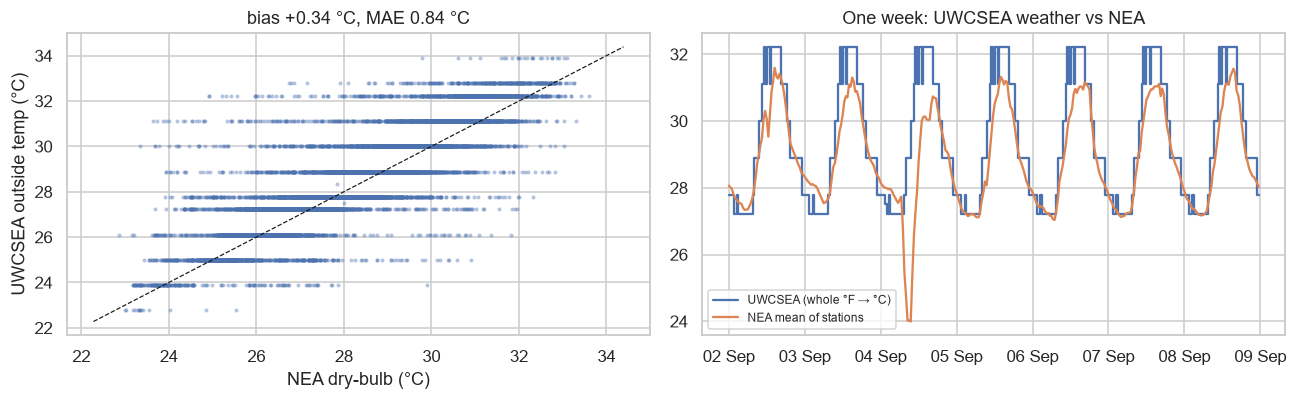

In [41]:
uw_nea = nea_site_30.shift(NEA_LAG_FOR_PLANT).reindex(uw_clean.index)
pair = pd.concat([uw_clean["oat_c"].rename("UWCSEA (whole °F → °C)"), uw_nea.rename("NEA mean of stations")], axis=1).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(pair.iloc[:, 1], pair.iloc[:, 0], s=3, alpha=0.3)
lim = [pair.min().min() - 0.5, pair.max().max() + 0.5]
axes[0].plot(lim, lim, "k--", lw=0.8)
axes[0].set_xlabel("NEA dry-bulb (°C)")
axes[0].set_ylabel("UWCSEA outside temp (°C)")
axes[0].set_title(f"bias {(pair.iloc[:, 0] - pair.iloc[:, 1]).mean():+.2f} °C, "
                  f"MAE {(pair.iloc[:, 0] - pair.iloc[:, 1]).abs().mean():.2f} °C")
wk = pair.loc["2019-09-02":"2019-09-08"]
axes[1].plot(wk.index, wk.iloc[:, 0], drawstyle="steps-post", label=wk.columns[0])
axes[1].plot(wk.index, wk.iloc[:, 1], label=wk.columns[1])
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=LOCAL_TZ))
axes[1].legend(fontsize=8)
axes[1].set_title("One week: UWCSEA weather vs NEA")
plt.tight_layout()
plt.show()

In [42]:
CSIT_SUM_COLS = ["chillers_kw", "chwp_kw", "cwp_kw", "ct_kw"]
csit_1min["plant_kw"] = csit_1min[CSIT_SUM_COLS].sum(axis=1, min_count=len(CSIT_SUM_COLS))
csit_1min["n_chillers_running"] = (csit_1min[["ch1_kw", "ch2_kw", "ch3_kw"]].gt(5)
                                   .where(csit_1min[["ch1_kw", "ch2_kw", "ch3_kw"]].notna()).sum(axis=1, min_count=3))
csit_15 = resample_mean(csit_1min, "15min").dropna(how="all")
print(f"CSIT 15-min table: {len(csit_15):,} buckets with any value; "
      f"{csit_15['plant_kw'].notna().sum():,} with plant kW; {csit_15['load_rt'].notna().sum():,} with load")
csit_15.describe().T[["count", "mean", "min", "max"]]

CSIT 15-min table: 2,213 buckets with any value; 299 with plant kW; 425 with load


,count,mean,min,max
load_rt,425.000,101.070,0.000,394.249
chillers_kw,314.000,56.825,0.493,199.202
chwp_kw,302.000,6.781,0.421,28.492
cwp_kw,317.000,5.950,0.000,10.796
ct_kw,317.000,1.354,0.000,5.123
ch1_kw,317.000,35.972,0.000,132.876
ch2_kw,233.000,15.451,0.006,93.263
ch3_kw,"1,652.000",1.776,0.000,75.920
chwp1_kw,317.000,2.298,0.000,7.538
chwp2_kw,317.000,0.777,0.003,3.398


### 3.4 Feature engineering
Features are built per dataset for the Section 7 models they will train. Lags and rolling windows use timestamps, not row positions, so gaps never pull in a value from the wrong time. Each forecast target sits one hour ahead of its features, as in Section 7.

| Group | Features |
|---|---|
| Calendar | hour, minute of day, day of week, weekend, Singapore public holiday, cyclical sin/cos of hour, day of week and day of year |
| Weather | NEA dry-bulb (UWCSEA, NEA); dew point, RH, wet-bulb (UWCSEA); NEA hourly climatology for the month (CSIT, which has no working weather sensor) |
| Plant | load in kW thermal, kW/RT, implied CHW ΔT, condenser water minus wet-bulb, today's tower setpoint by the BMS formula (UWCSEA); plant kW, chillers running, part-load ratio, AHU power (CSIT) |
| History | load lags of 15 min to one week, rolling means; dry-bulb lags and rolling stats (NEA) |
| Regime | UWCSEA `circuit_breaker` flag from 7 Apr 2020 (COVID-19 measures changed building use) |

In [43]:
# Singapore public holidays inside the UWCSEA window, observed dates.
# None fall inside the CSIT window (1 Sep - 15 Oct 2026).
SG_HOLIDAYS = pd.to_datetime([
    "2019-10-28", "2019-12-25", "2020-01-01", "2020-01-25", "2020-01-27",
    "2020-04-10", "2020-05-01", "2020-05-07", "2020-05-25",
]).date
CIRCUIT_BREAKER_START = pd.Timestamp("2020-04-07", tz=LOCAL_TZ)


def add_calendar(df):
    out = df.copy()
    idx = out.index
    out["hour"] = idx.hour
    out["minute_of_day"] = idx.hour * 60 + idx.minute
    out["dayofweek"] = idx.dayofweek
    out["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    out["is_holiday"] = pd.Index(idx.date).isin(SG_HOLIDAYS).astype(int)
    out["is_workday"] = ((out["is_weekend"] == 0) & (out["is_holiday"] == 0)).astype(int)
    tod = out["minute_of_day"] / 1440
    out["hour_sin"], out["hour_cos"] = np.sin(2 * np.pi * tod), np.cos(2 * np.pi * tod)
    out["dow_sin"], out["dow_cos"] = np.sin(2 * np.pi * idx.dayofweek / 7), np.cos(2 * np.pi * idx.dayofweek / 7)
    out["doy_sin"], out["doy_cos"] = np.sin(2 * np.pi * idx.dayofyear / 365.25), np.cos(2 * np.pi * idx.dayofyear / 365.25)
    return out


def add_lags(df, col, lags, prefix=None):
    """Value of `col` at t - lag, looked up by timestamp."""
    prefix = prefix or col
    for lag in lags:
        df[f"{prefix}_lag_{lag}"] = df[col].shift(freq=pd.Timedelta(lag)).reindex(df.index)
    return df


def add_rolling(df, col, windows, stats=("mean",), prefix=None):
    """Trailing time-window statistics, including the current value."""
    prefix = prefix or col
    for w in windows:
        r = df[col].rolling(pd.Timedelta(w), min_periods=1)
        for stat in stats:
            df[f"{prefix}_roll{stat}_{w}"] = getattr(r, stat)()
    return df


def add_target(df, col, horizon, name):
    df[name] = df[col].shift(freq=-pd.Timedelta(horizon)).reindex(df.index)
    return df

In [44]:
# ---- UWCSEA (30 min) ------------------------------------------------------
uwf = add_calendar(uw_clean)
uwf["regime"] = np.where(uwf.index >= CIRCUIT_BREAKER_START, "circuit_breaker", "normal")
uwf["drybulb_c"] = uw_nea.combine_first(uwf["oat_c"])           # NEA 0.1 °C where available, else UWCSEA
uwf["drybulb_source"] = np.where(uw_nea.notna(), "NEA", np.where(uwf["oat_c"].notna(), "UWCSEA", "none"))
uwf["rh_pct_at_drybulb"] = rh_from_t_td(uwf["drybulb_c"], uwf["dewpoint_c"]).clip(upper=100)
uwf["wetbulb_c"] = wet_bulb_stull(uwf["drybulb_c"], uwf["rh_pct_at_drybulb"])
uwf["load_kwth"] = rt_to_kw(uwf["load_rt"])
uwf["kw_per_rt"] = uwf["chiller_kw"] / uwf["load_rt"]
uwf["chw_dt_implied_c"] = implied_delta_t(uwf["load_kwth"], uwf["chw_flow_lps"])
uwf["cw_minus_wb_c"] = uwf["cw_temp_c"] - uwf["wetbulb_c"]
uwf["ct_setpoint_today_c"] = ct_setpoint_today(uwf["wetbulb_c"])
uwf = add_lags(uwf, "load_rt", ["30min", "1h", "2h", "1D", "7D"])
uwf = add_rolling(uwf, "load_rt", ["2h", "1D"])
uwf = add_lags(uwf, "drybulb_c", ["1h"])
uwf = add_rolling(uwf, "drybulb_c", ["3h"])
uwf = add_target(uwf, "load_rt", "1h", "target_load_rt_next1h")
uwf["target_chiller_kw"] = uwf["chiller_kw"]
print(uwf.shape)
uwf.filter(regex="load|target|wetbulb|drybulb").describe().T[["count", "mean", "min", "max"]]

(13851, 42)


,count,mean,min,max
load_rt,"13,385.000",520.871,139.000,948.500
drybulb_c,"13,851.000",28.049,22.871,33.602
rh_pct_at_drybulb,"13,626.000",78.855,37.425,100.000
wetbulb_c,"13,626.000",25.023,20.930,27.995
load_kwth,"13,385.000","1,831.826",488.842,"3,335.732"
load_rt_lag_30min,"13,384.000",520.868,139.000,948.500
load_rt_lag_1h,"13,383.000",520.864,139.000,948.500
load_rt_lag_2h,"13,381.000",520.858,139.000,948.500
load_rt_lag_1D,"13,337.000",521.087,139.000,948.500
load_rt_lag_7D,"13,049.000",522.125,139.000,948.500


In [45]:
# ---- CSIT (15 min) --------------------------------------------------------
nea_best_csit = nea_catalogue.nsmallest(1, "km_to_CSIT").index[0]
clim = nea_15min[nea_best_csit].groupby([nea_15min.index.month, nea_15min.index.hour]).mean()

csf = add_calendar(csit_15)
csf["drybulb_clim_c"] = clim.reindex(list(zip(csf.index.month, csf.index.hour))).to_numpy()
csf["load_kwth"] = rt_to_kw(csf["load_rt"])
csf["plant_kw_per_rt"] = (csf["plant_kw"] / csf["load_rt"]).where(csf["load_rt"] >= 30)
csf["chillers_kw_per_rt"] = (csf["chillers_kw"] / csf["load_rt"]).where(csf["load_rt"] >= 30)
csf["part_load_ratio"] = csf["load_rt"] / (PLANT["chiller_capacity_rt"] * csf["n_chillers_running"].round().clip(lower=1))
csf = add_lags(csf, "load_rt", ["15min", "30min", "1h", "1D"])
csf = add_rolling(csf, "load_rt", ["1h"])
csf = add_lags(csf, "ahu_kw_total", ["15min"])
csf = add_target(csf, "load_rt", "1h", "target_load_rt_next1h")
csf["target_plant_kw"] = csf["plant_kw"]
print(f"Climatology from NEA station {nea_best_csit} ({nea_catalogue.loc[nea_best_csit, 'station_name']})")
print(csf.shape)
csf.filter(regex="load|plant_kw|part_load|clim|target").describe().T[["count", "mean", "min", "max"]]

Climatology from NEA station S116 (West Coast Highway)
(2213, 45)


,count,mean,min,max
load_rt,425.000,101.070,0.000,394.249
plant_kw,299.000,74.211,4.163,221.110
drybulb_clim_c,"2,213.000",28.510,27.168,29.543
load_kwth,425.000,355.449,0.000,"1,386.515"
plant_kw_per_rt,230.000,0.506,0.037,0.688
load_rt_lag_15min,421.000,100.019,0.000,394.249
load_rt_lag_30min,418.000,99.400,0.000,394.249
load_rt_lag_1h,415.000,99.058,0.000,394.249
load_rt_lag_1D,321.000,73.342,0.000,394.249
load_rt_rollmean_1h,431.000,100.411,0.000,314.385


In [46]:
# ---- NEA (15 min, site dry-bulb) -----------------------------------------
nef = add_calendar(nea_site_15[["drybulb_c", "n_stations"]])
nef = add_lags(nef, "drybulb_c", ["15min", "30min", "45min", "1h", "2h", "3h", "1D"])
nef["drybulb_diff_15min"] = nef["drybulb_c"] - nef["drybulb_c_lag_15min"]
nef = add_rolling(nef, "drybulb_c", ["1h", "3h"], stats=("mean", "std", "max"))
nef = add_target(nef, "drybulb_c", "1h", "target_drybulb_next1h")
print(nef.shape)
nef.filter(regex="drybulb_c$|lag_1h|target").describe().T[["count", "mean", "min", "max"]]

(305492, 29)


,count,mean,min,max
drybulb_c,"294,655.000",27.950,21.622,33.856
drybulb_c_lag_1h,"294,651.000",27.950,21.622,33.856
target_drybulb_next1h,"294,654.000",27.950,21.622,33.856


In [47]:
FEATURES = {
    "uwcsea": {
        "calendar": ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend", "is_holiday", "is_workday"],
        "weather": ["drybulb_c", "dewpoint_c", "rh_pct_at_drybulb", "wetbulb_c", "wind_ms", "pressure_kpa",
                    "drybulb_c_lag_1h", "drybulb_c_rollmean_3h"],
        "plant": ["load_rt", "load_kwth", "chw_flow_lps", "cw_temp_c", "chw_dt_implied_c", "cw_minus_wb_c", "ct_setpoint_today_c"],
        "history": ["load_rt_lag_30min", "load_rt_lag_1h", "load_rt_lag_2h", "load_rt_lag_1D", "load_rt_lag_7D",
                    "load_rt_rollmean_2h", "load_rt_rollmean_1D"],
        "targets": {"cooling_demand_forecast": "target_load_rt_next1h", "baseline / chiller kW": "target_chiller_kw"},
    },
    "csit": {
        "calendar": ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_weekend", "is_holiday", "is_workday"],
        "weather": ["drybulb_clim_c"],
        "plant": ["load_rt", "load_kwth", "n_chillers_running", "part_load_ratio", "ahu_kw_total",
                  "ch1_kw", "ch2_kw", "ch3_kw", "chwp_kw", "cwp_kw", "ct_kw"],
        "history": ["load_rt_lag_15min", "load_rt_lag_30min", "load_rt_lag_1h", "load_rt_lag_1D", "load_rt_rollmean_1h",
                    "ahu_kw_total_lag_15min"],
        "targets": {"cooling_demand_forecast": "target_load_rt_next1h", "baseline": "target_plant_kw"},
    },
    "nea": {
        "calendar": ["hour_sin", "hour_cos", "doy_sin", "doy_cos"],
        "history": [c for c in nef.columns if c.startswith("drybulb_c_") or c == "drybulb_diff_15min"],
        "weather": ["drybulb_c"],
        "targets": {"weather_forecast": "target_drybulb_next1h"},
    },
}
{k: {g: len(v) for g, v in d.items()} for k, d in FEATURES.items()}

{'uwcsea': {'calendar': 9,
  'weather': 8,
  'plant': 7,
  'history': 7,
  'targets': 2},
 'csit': {'calendar': 7,
  'weather': 1,
  'plant': 11,
  'history': 6,
  'targets': 2},
 'nea': {'calendar': 4, 'history': 14, 'weather': 1, 'targets': 1}}

### 3.5 Chronological train / validation / test splits
Splits follow time, never random rows. Document Section 7 keeps the most recent two weeks aside as test days; the validation window sits just before it, and training uses everything earlier. A one-hour embargo before each boundary stops a training row's next-hour target from reaching into the following split.

* **UWCSEA**: the COVID-19 circuit breaker (from 7 Apr 2020) changed how the building was used, the "plant unchanged" assumption in Section 12. Those weeks are kept out of train/val/test and saved separately as a regime-shift stress set. Test is the 14 days before 7 Apr, validation the 14 days before that.
* **CSIT**: only a few days hold plant data, so two weeks of test days is not possible. The last day with data is test, the day before is validation, the rest is train. These splits are a smoke test for transfer to the target plant, not a Section 7 acceptance test.
* **NEA**: by calendar year. 2016–2022 train, 2023 validation, 2024 test.

In [48]:
def chrono_split(df, *, val_days, test_days, embargo="1h", require=None):
    """Last `test_days` dates with data -> test, the `val_days` before -> validation, the rest -> train."""
    base = df if require is None else df[df[require].notna()]
    dates = pd.DatetimeIndex(base.index.normalize().unique()).sort_values()
    test_start, val_start = dates[-test_days], dates[-(test_days + val_days)]
    emb = pd.Timedelta(embargo)
    return {
        "train": df[df.index < val_start - emb],
        "val": df[(df.index >= val_start) & (df.index < test_start - emb)],
        "test": df[df.index >= test_start],
    }


def split_by_time(df, val_start, test_start, embargo="1h"):
    val_start, test_start = pd.Timestamp(val_start, tz=LOCAL_TZ), pd.Timestamp(test_start, tz=LOCAL_TZ)
    emb = pd.Timedelta(embargo)
    return {"train": df[df.index < val_start - emb],
            "val": df[(df.index >= val_start) & (df.index < test_start - emb)],
            "test": df[df.index >= test_start]}


def split_summary(splits, target):
    rows = []
    for name, part in splits.items():
        y = part[target]
        rows.append({"split": name, "rows": len(part), "rows_with_target": int(y.notna().sum()),
                     "start": part.index.min(), "end": part.index.max(),
                     "days": part.index.normalize().nunique(), "target_mean": y.mean()})
    return pd.DataFrame(rows).set_index("split")


uw_normal = uwf[uwf["regime"] == "normal"]
uw_regime_shift = uwf[uwf["regime"] == "circuit_breaker"]
SPLITS = {
    "uwcsea": chrono_split(uw_normal, val_days=14, test_days=PLANT["test_window_days"], require="target_load_rt_next1h"),
    "csit": chrono_split(csf, val_days=1, test_days=1, require="target_plant_kw"),
    "nea": split_by_time(nef, "2023-01-01", "2024-01-01"),
}
TARGET_FOR_SUMMARY = {"uwcsea": "target_load_rt_next1h", "csit": "target_plant_kw", "nea": "target_drybulb_next1h"}
summaries = {k: split_summary(v, TARGET_FOR_SUMMARY[k]) for k, v in SPLITS.items()}
summaries["uwcsea"] = pd.concat([summaries["uwcsea"],
                                 split_summary({"regime_shift": uw_regime_shift}, "target_load_rt_next1h")])
summary = pd.concat(summaries)
summary

rows  rows_with_target                     start                       end  days  target_mean
       split                                                                                                        
uwcsea train           9838              9388 2019-08-18 00:00:00+08:00 2020-03-09 22:30:00+08:00   205      531.161
       val              670               658 2020-03-10 00:00:00+08:00 2020-03-23 22:30:00+08:00    14      556.657
       test             672               668 2020-03-24 00:00:00+08:00 2020-04-06 23:30:00+08:00    14      557.740
       regime_shift    2667              2665 2020-04-07 00:00:00+08:00 2020-06-01 13:00:00+08:00    56      466.709
csit   train           2026               112 2026-09-01 19:15:00+08:00 2026-10-13 22:45:00+08:00    23       42.713
       val               92                92 2026-10-14 00:00:00+08:00 2026-10-14 22:45:00+08:00     1       92.950
       test              87                87 2026-10-15 00:00:00+08:00 2026-10-15 21:30:00+08:00     1       97.301
nea    train         235312            225691 2016-04-15 19:00:00+08:00 2022-12-31 22:45:00+08:00  2452       27.898
       val            35036             33991 2023-01-01 00:00:00+08:00 2023-12-31 22:45:00+08:00   365       27.924
       test           35136             34964 2024-01-01 00:00:00+08:00 2024-12-31 23:45:00+08:00   366       28.313

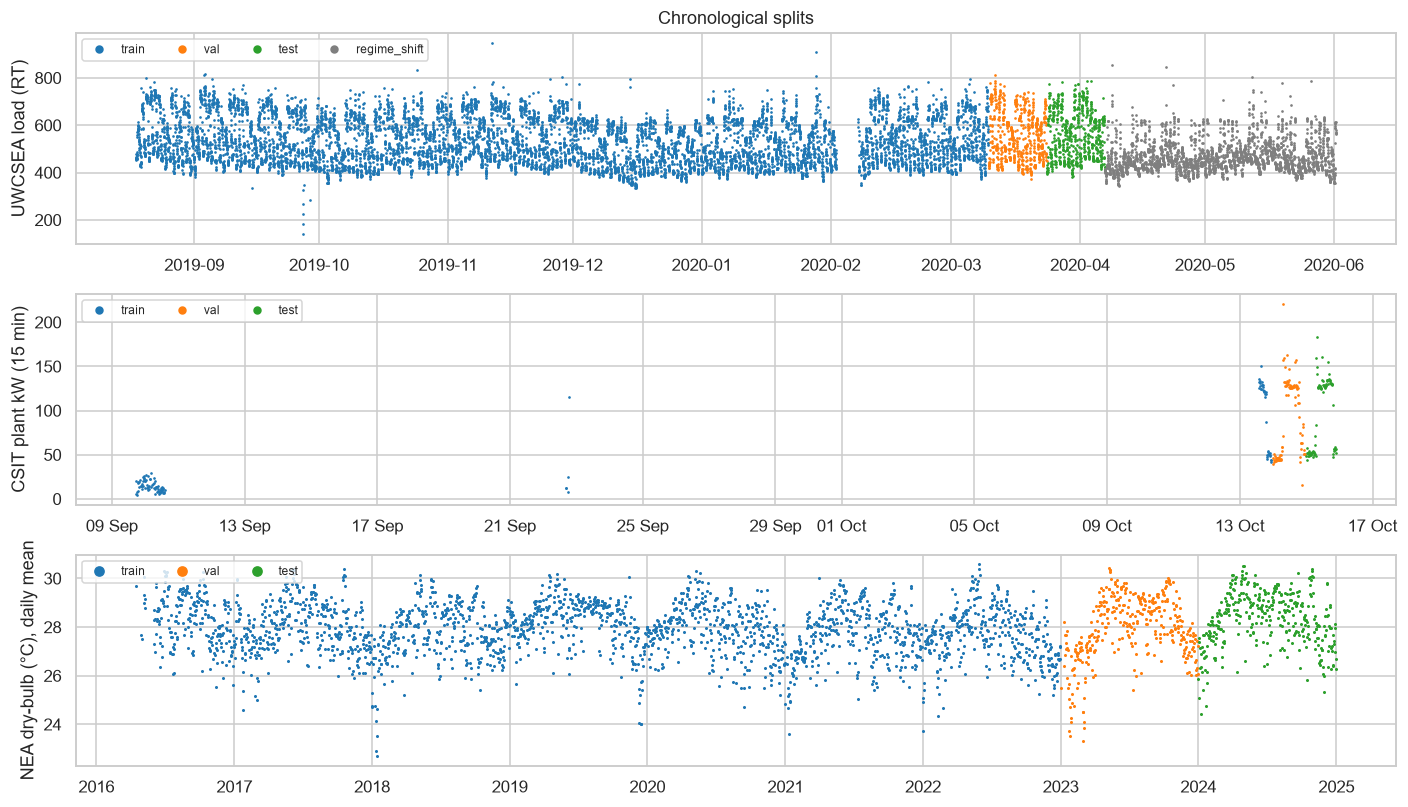

In [49]:
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green", "regime_shift": "tab:grey"}
fig, axes = plt.subplots(3, 1, figsize=(13, 7.5))
panels = [("uwcsea", "load_rt", "UWCSEA load (RT)"), ("csit", "plant_kw", "CSIT plant kW (15 min)"),
          ("nea", "drybulb_c", "NEA dry-bulb (°C), daily mean")]
for ax, (name, col, label) in zip(axes, panels):
    parts = dict(SPLITS[name])
    if name == "uwcsea":
        parts["regime_shift"] = uw_regime_shift
    for split, part in parts.items():
        y = part[col].resample("D").mean() if name == "nea" else part[col]
        ax.plot(y.index, y.values, ".", ms=1.5 if name != "nea" else 2, color=colors[split], label=split)
    ax.set_ylabel(label)
    ax.legend(markerscale=6, fontsize=8, loc="upper left", ncol=4)
    if name == "csit":
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=LOCAL_TZ))
axes[0].set_title("Chronological splits")
plt.tight_layout()
plt.show()

### 3.6 Save the processed datasets
Each split goes to `processed_data/` as parquet, with time-zone-aware timestamps. A JSON file records the feature lists, targets, split boundaries and cleaning rules, so Part 4 and later refits load exactly the same data.

In [50]:
saved = []
for name, parts in SPLITS.items():
    for split, part in parts.items():
        path = OUT_DIR / f"{name}_{split}.parquet"
        part.to_parquet(path)
        saved.append({"file": path.name, "rows": len(part), "columns": part.shape[1]})
path = OUT_DIR / "uwcsea_regime_shift.parquet"
uw_regime_shift.to_parquet(path)
saved.append({"file": path.name, "rows": len(uw_regime_shift), "columns": uw_regime_shift.shape[1]})
csit_1min.to_parquet(OUT_DIR / "csit_clean_1min.parquet")
saved.append({"file": "csit_clean_1min.parquet", "rows": len(csit_1min), "columns": csit_1min.shape[1]})

pd.concat({"uwcsea": uw_log, "csit": csit_log, "nea": nea_log}).to_csv(OUT_DIR / "cleaning_log.csv")

metadata = {
    "created_by": "Chiller_Plant_Model_Training_Validation.ipynb",
    "time_zone": LOCAL_TZ,
    "features": FEATURES,
    "splits": {name: {split: [str(p.index.min()), str(p.index.max()), len(p)] for split, p in parts.items()}
               for name, parts in SPLITS.items()},
    "uwcsea_regime_shift": [str(uw_regime_shift.index.min()), str(uw_regime_shift.index.max()), len(uw_regime_shift)],
    "nea_stations": NEA_SELECTED, "nea_lag_steps_for_uwcsea": NEA_LAG_FOR_PLANT,
    "cleaning": {"uwcsea_max_gap_samples": 2, "csit_max_gap_minutes": 5, "nea_max_gap_minutes": 5,
                 "limits": {"uwcsea": UW_LIMITS, "csit": CSIT_LIMITS, "nea": {"drybulb_c": [18, 40]}}},
    "plant": PLANT,
}
(OUT_DIR / "dataset_metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
saved.append({"file": "dataset_metadata.json"})
saved.append({"file": "cleaning_log.csv"})
pd.DataFrame(saved)

,file,rows,columns
0,uwcsea_train.parquet,"9,838.000",42.000
1,uwcsea_val.parquet,670.000,42.000
2,uwcsea_test.parquet,672.000,42.000
3,csit_train.parquet,"2,026.000",45.000
4,csit_val.parquet,92.000,45.000
5,csit_test.parquet,87.000,45.000
6,nea_train.parquet,"235,312.000",29.000
7,nea_val.parquet,"35,036.000",29.000
8,nea_test.parquet,"35,136.000",29.000
9,uwcsea_regime_shift.parquet,"2,667.000",42.000


### 3.7 Summary and next steps
**Produced in `processed_data/`**

| File | Content |
|---|---|
| `uwcsea_{train,val,test}.parquet` | 30-min features and targets. Train runs 18 Aug 2019 to 9 Mar 2020, validation 10 to 23 Mar, test 24 Mar to 6 Apr 2020 |
| `uwcsea_regime_shift.parquet` | circuit-breaker weeks, 7 Apr to 1 Jun 2020, as a stress set |
| `csit_{train,val,test}.parquet` | 15-min features and targets; test is 15 Oct 2026, validation 14 Oct |
| `csit_clean_1min.parquet` | cleaned 1-min CSIT plant tags, for future chiller curves |
| `nea_{train,val,test}.parquet` | 15-min site dry-bulb features; 2016 to 2022 train, 2023 validation, 2024 test |
| `dataset_metadata.json`, `cleaning_log.csv` | feature lists, targets, split boundaries, limits and every removed value |

**Departures from the original code:** splits now include a validation window and a one-hour embargo; short gaps are interpolated instead of forward and back filled; sensor faults are removed instead of copied forward; time zones are explicit; and the weather comes from NEA at 0.1 °C instead of whole °F.

**Next:** Sections 4 – 9 train the models the data support now: cooling load, weather, total chiller power and the energy baseline. Models 4 and 5 keep their section titles and a data check until CSIT provides the measurements.

## 4. Model 1: Cooling Load Prediction

Section 7 asks for a forecast of the cooling load one hour ahead. With the data available now it is trained on **UWCSEA**, the only dataset with months of load history. CSIT holds about 3 days of load, too little to fit or test this model on.

### 4.1 Shared training and evaluation tools
Every model below uses the same tools:

* **Data:** rows with a missing feature or target are dropped, so every model is scored on the same rows.
* **Models:** the original model zoo from Section 1.3, plus LightGBM (gradient-boosted trees, the method Section 7 names). LightGBM uses the validation split only to decide when to stop adding trees.
* **Selection:** the model with the best validation score is selected. The test split is scored once, for reporting.
* **Metrics:** MAE, RMSE, R², MAPE, CV(RMSE) (the original `cvrmse`) and NMBE, plus the share of predictions that land within the Section 7 tolerance.

Section 7 gives each tolerance (for example "within 5 %") but not the statistic behind it. The reading used here is in `ACCEPTANCE` below.

In [51]:
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RESULTS_DIR = ROOT / "results"
FIG_DIR, MODEL_DIR, TABLE_DIR = RESULTS_DIR / "figures", RESULTS_DIR / "models", RESULTS_DIR / "tables"
for d in (FIG_DIR, MODEL_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

FIGURES = []           # file names of every saved figure
ALL_METRICS = []       # metric tables of every model task
TRAINED = {}           # task -> {"models", "features", "target", "selected", "test_pred"}

# How each Section 7 tolerance is read in this notebook
ACCEPTANCE = pd.DataFrame([
    ("Model 1: cooling load", "MAPE_%", 5.0, "mean absolute % error of the next-hour load ≤ 5 %"),
    ("Model 2: weather", "MAE", 1.0, "mean absolute error of the next-hour dry-bulb ≤ 1 °C"),
    ("Model 3: chiller power", "MAPE_%", 3.0, "mean absolute % error of chiller kW ≤ 3 %"),
    ("Model 4: cooling tower", "MAE", 0.3, "mean absolute error of tower leaving water ≤ 0.3 °C"),
    ("Model 5: pump and fan power", "MAPE_%", 3.0, "mean absolute % error of pump / fan kW ≤ 3 %"),
    ("Model 6: energy baseline", "|NMBE|_%", 5.0, "total energy over the test period within ± 5 %"),
], columns=["task", "metric", "limit", "meaning"]).set_index("task")


def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    FIGURES.append(path.name)


def regression_metrics(y, p, tol=None):
    """tol = ("rel", 0.05) or ("abs", 1.0): share of predictions within that tolerance."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    err = p - y
    nz = np.abs(y) > 1e-6
    out = {"n": len(y), "MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))),
           "R2": r2_score(y, p), "MAPE_%": 100 * np.mean(np.abs(err[nz] / y[nz])),
           "CV(RMSE)_%": 100 * float(orig.cvrmse(y, p)), "NMBE_%": 100 * err.sum() / y.sum()}
    out["|NMBE|_%"] = abs(out["NMBE_%"])
    if tol:
        kind, v = tol
        within = np.abs(err) <= (v * np.abs(y) if kind == "rel" else v)
        out["within_tol_%"] = 100 * within.mean()
    return out


def prepare_xy(splits, features, target):
    data = {}
    for split, df in splits.items():
        d = df[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()
        data[split] = (d[features], d[target])
    return data


def lightgbm_model(seed=SEED, **kw):
    params = dict(n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1)
    return lightgbm.LGBMRegressor(**(params | kw))


def fit_and_score(task, data, models, *, tol=None, persistence=None):
    """Fit every model on train and score it on every split. `persistence` names a feature used as a naive forecast."""
    X_tr, y_tr = data["train"]
    X_va, y_va = data["val"]
    rows, fitted, preds = [], {}, {}
    for name, model in models.items():
        if isinstance(model, lightgbm.LGBMRegressor):
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lightgbm.early_stopping(100, verbose=False)])
        else:
            model.fit(X_tr, y_tr)
        fitted[name] = model
        for split, (X, y) in data.items():
            p = pd.Series(model.predict(X), index=X.index)
            preds[(name, split)] = p
            rows.append({"task": task, "model": name, "split": split, **regression_metrics(y, p, tol)})
    if persistence:
        for split, (X, y) in data.items():
            preds[("persistence", split)] = X[persistence]
            rows.append({"task": task, "model": "persistence", "split": split,
                         **regression_metrics(y, X[persistence], tol)})
    metrics = pd.DataFrame(rows)
    ALL_METRICS.append(metrics)
    return fitted, preds, metrics


def select_model(metrics, metric):
    val = metrics[(metrics["split"] == "val") & (metrics["model"] != "persistence")]
    return val.loc[val[metric].idxmin(), "model"]


def metric_table(metrics, cols=("MAE", "RMSE", "R2", "MAPE_%", "CV(RMSE)_%", "NMBE_%", "within_tol_%")):
    cols = [c for c in cols if c in metrics]
    return metrics.pivot_table(index="model", columns="split", values=cols, sort=False)[cols].reorder_levels(
        [1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False, key=lambda s: s.map({"train": 0, "val": 1, "test": 2}))


def plot_actual_vs_pred(y, p, title, unit, name, days=7):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
    axes[0].scatter(y, p, s=4, alpha=0.4)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    axes[0].plot(lim, lim, "k--", lw=0.8)
    axes[0].set_xlabel(f"actual ({unit})")
    axes[0].set_ylabel(f"predicted ({unit})")
    axes[0].set_title(f"R² = {r2_score(y, p):.3f}")
    end = y.index.min() + pd.Timedelta(days=days)
    axes[1].plot(y.loc[:end].index, y.loc[:end], lw=1.0, label="actual")
    axes[1].plot(p.loc[:end].index, p.loc[:end], lw=1.0, label="predicted")
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=LOCAL_TZ))
    axes[1].set_ylabel(unit)
    axes[1].set_title(f"first {days} test days")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()


def plot_importance(model, features, title, name, top=15):
    imp = pd.Series(model.booster_.feature_importance("gain"), index=features)
    imp = (imp / imp.sum() * 100).sort_values().tail(top)
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(imp) + 1))
    imp.plot.barh(ax=ax)
    ax.set_xlabel("share of total gain (%)")
    ax.set_title(title)
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()
    return imp.sort_values(ascending=False)


ACCEPTANCE

,metric,limit,meaning
task,,,
Model 1: cooling load,MAPE_%,5.000,mean absolute % error of the next-hour load ≤ 5 %
Model 2: weather,MAE,1.000,mean absolute error of the next-hour dry-bulb ...
Model 3: chiller power,MAPE_%,3.000,mean absolute % error of chiller kW ≤ 3 %
Model 4: cooling tower,MAE,0.300,mean absolute error of tower leaving water ≤ 0...
Model 5: pump and fan power,MAPE_%,3.000,mean absolute % error of pump / fan kW ≤ 3 %
Model 6: energy baseline,|NMBE|_%,5.000,total energy over the test period within ± 5 %


### 4.2 Data and features
Target: building load one hour ahead (`target_load_rt_next1h`), on the 30-min UWCSEA grid. Features known at time *t*: calendar, NEA dry-bulb and the derived wet-bulb, the current load and its history, and the operating data on record (chilled-water flow, cooling-water temperature). The splits are those from Section 3.5: train to 9 Mar 2020, validation 10–23 Mar, test 24 Mar – 6 Apr. The circuit-breaker weeks are scored separately.

In [52]:
M1_TASK = "Model 1: cooling load"
M1_TARGET = "target_load_rt_next1h"
M1_FEATURES = (FEATURES["uwcsea"]["calendar"]
               + ["drybulb_c", "wetbulb_c", "rh_pct_at_drybulb", "drybulb_c_lag_1h", "drybulb_c_rollmean_3h"]
               + ["load_rt", "chw_flow_lps", "cw_temp_c"] + FEATURES["uwcsea"]["history"])
m1_data = prepare_xy(SPLITS["uwcsea"], M1_FEATURES, M1_TARGET)
pd.DataFrame({s: {"rows": len(y), "start": y.index.min(), "end": y.index.max(), "mean target (RT)": y.mean()}
              for s, (X, y) in m1_data.items()}).T

,rows,start,end,mean target (RT)
train,8256,2019-08-25 00:00:00+08:00,2020-03-09 22:30:00+08:00,528.813
val,606,2020-03-10 00:00:00+08:00,2020-03-23 22:30:00+08:00,555.361
test,650,2020-03-24 00:00:00+08:00,2020-04-06 23:30:00+08:00,559.078


### 4.3 Train

In [53]:
m1_models = {**original_model_zoo(), "lightgbm": lightgbm_model()}
m1_fitted, m1_pred, m1_metrics = fit_and_score(M1_TASK, m1_data, m1_models, tol=("rel", 0.05), persistence="load_rt")
M1_SELECTED = select_model(m1_metrics, "MAPE_%")
print("Selected on validation MAPE:", M1_SELECTED)

Selected on validation MAPE: lightgbm


### 4.4 Validate and test
`persistence` repeats the current load as the forecast for the next hour. A model only adds value if it beats persistence.

split              train                                                       val                                                      test                                                   
                     MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%
model                                                                                                                                                                                          
linear_regression 23.954 35.048 0.862  4.522      6.628 -0.000       66.982 24.624 34.699 0.875  4.406      6.248  0.118       66.502 23.965 33.370 0.887  4.245      5.969  0.466       68.923
ridge             23.952 35.048 0.862  4.522      6.628  0.000       67.006 24.618 34.695 0.875  4.405      6.247  0.120       66.502 23.961 33.367 0.887  4.244      5.968  0.467       68.923
random_forest      9.399 15.717 0.972  1.741      2.972  0.007       93.774 17.830 25.976 0.930  3.098      4.677 -0.124       81.848 18.400 26.255 0.930  3.157      4.696  0.109       80.923
mlp               14.730 21.975 0.946  2.733      4.156 -0.216       86.434 20.427 28.580 0.915  3.624      5.146  0.512       78.218 22.412 29.774 0.910  3.993      5.326  1.531       69.077
lightgbm          12.001 17.786 0.965  2.247      3.363 -0.002       90.770 17.349 25.381 0.933  3.029      4.570  0.293       81.023 18.384 26.291 0.930  3.154      4.702  0.642       80.615
persistence       27.203 44.331 0.780  5.025      8.383  0.026       67.963 28.556 44.828 0.791  5.024      8.072  0.243       65.842 29.126 43.692 0.806  5.063      7.815  0.078       63.692

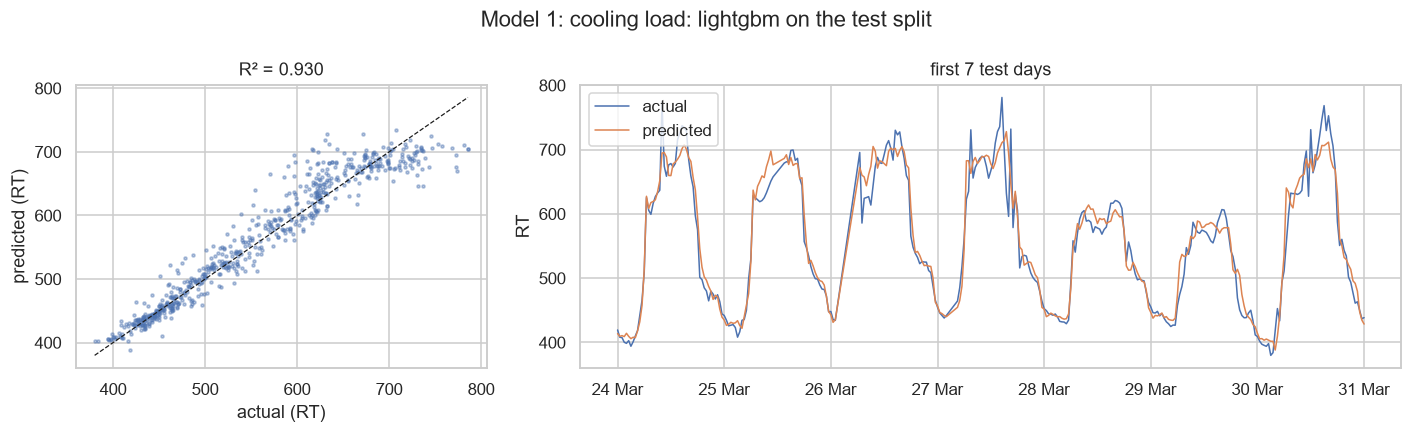

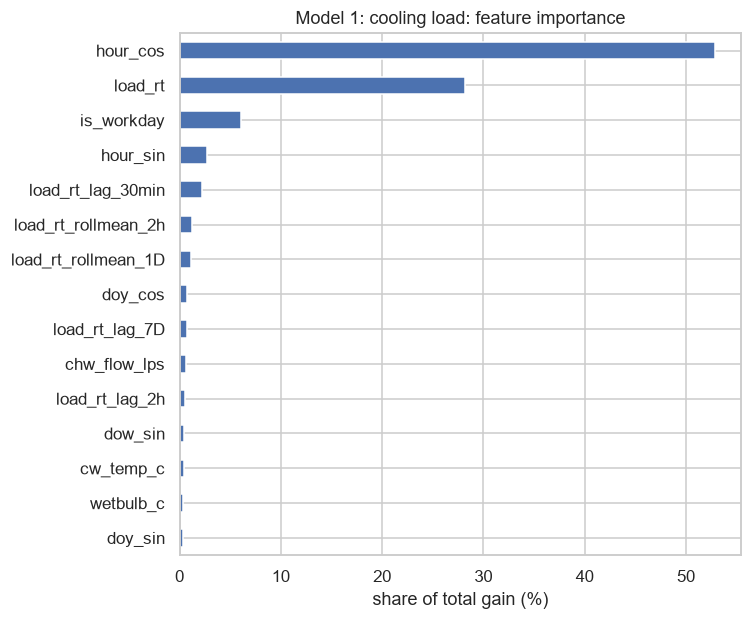

In [54]:
display(metric_table(m1_metrics))
X_te, y_te = m1_data["test"]
plot_actual_vs_pred(y_te, m1_pred[(M1_SELECTED, "test")], f"{M1_TASK}: {M1_SELECTED} on the test split",
                    "RT", "model1_cooling_load_actual_vs_predicted")
if M1_SELECTED == "lightgbm":
    m1_importance = plot_importance(m1_fitted["lightgbm"], M1_FEATURES, f"{M1_TASK}: feature importance",
                                    "model1_cooling_load_importance")

In [55]:
# Regime-shift stress test: the circuit-breaker weeks, never seen in training or selection
m1_shift = prepare_xy({"regime_shift": uw_regime_shift}, M1_FEATURES, M1_TARGET)["regime_shift"]
shift_rows = [{"model": n, **regression_metrics(m1_shift[1], m.predict(m1_shift[0]), ("rel", 0.05))}
              for n, m in m1_fitted.items()]
shift_rows.append({"model": "persistence", **regression_metrics(m1_shift[1], m1_shift[0]["load_rt"], ("rel", 0.05))})
m1_shift_metrics = pd.DataFrame(shift_rows).set_index("model")
ALL_METRICS.append(m1_shift_metrics.reset_index().assign(task=M1_TASK, split="regime_shift"))
m1_shift_metrics[["n", "MAE", "RMSE", "R2", "MAPE_%", "NMBE_%", "within_tol_%"]]

,n,MAE,RMSE,R2,MAPE_%,NMBE_%,within_tol_%
model,,,,,,,
linear_regression,2651,35.518,46.677,0.504,7.546,5.770,43.003
ridge,2651,35.494,46.654,0.505,7.541,5.764,43.078
random_forest,2651,45.743,70.005,-0.115,9.464,8.366,52.773
mlp,2651,61.607,79.760,-0.447,13.097,12.103,21.728
lightgbm,2651,38.748,56.089,0.284,8.098,6.999,52.659
persistence,2651,23.118,40.610,0.625,4.585,-0.027,72.124


In [56]:
TRAINED[M1_TASK] = {"models": m1_fitted, "features": M1_FEATURES, "target": M1_TARGET, "selected": M1_SELECTED,
                    "unit": "RT", "test_actual": y_te, "test_pred": m1_pred[(M1_SELECTED, "test")]}

## 5. Model 2: Weather Forecasting

Trained and evaluated independently on **NEA**. Target: site dry-bulb one hour ahead (mean of the selected stations, 15-min steps). Section 7 also asks for humidity, but the NEA files hold dry-bulb only. The CSIT weather station is faulty and UWCSEA's humidity is whole-percent and does not overlap CSIT, so **the humidity forecast is not trained**.

Splits: train 2016 – 2022, validation 2023, test 2024. With about 225,000 training rows the random forest and MLP of the original zoo would be slow and very large on disk, and they add little for a smooth signal like this. Linear models and LightGBM are compared against persistence.

In [57]:
M2_TASK = "Model 2: weather"
M2_TARGET = "target_drybulb_next1h"
M2_FEATURES = FEATURES["nea"]["calendar"] + FEATURES["nea"]["weather"] + FEATURES["nea"]["history"]
m2_data = prepare_xy(SPLITS["nea"], M2_FEATURES, M2_TARGET)
print({s: len(y) for s, (X, y) in m2_data.items()})
m2_models = {"linear_regression": LinearRegression(), "ridge": Ridge(alpha=1.0), "lightgbm": lightgbm_model()}
m2_fitted, m2_pred, m2_metrics = fit_and_score(M2_TASK, m2_data, m2_models, tol=("abs", 1.0), persistence="drybulb_c")
M2_SELECTED = select_model(m2_metrics, "MAE")
print("Selected on validation MAE:", M2_SELECTED)
metric_table(m2_metrics, ("MAE", "RMSE", "R2", "NMBE_%", "within_tol_%"))

{'train': 214876, 'val': 33503, 'test': 34709}


Selected on validation MAE: lightgbm


split             train                                   val                                  test                                
                    MAE  RMSE    R2 NMBE_% within_tol_%   MAE  RMSE    R2 NMBE_% within_tol_%   MAE  RMSE    R2 NMBE_% within_tol_%
model                                                                                                                              
linear_regression 0.373 0.612 0.897 -0.000       93.013 0.380 0.632 0.903 -0.010       92.604 0.382 0.621 0.892 -0.168       92.449
ridge             0.373 0.612 0.897 -0.000       93.014 0.380 0.632 0.903 -0.010       92.604 0.382 0.621 0.892 -0.168       92.449
lightgbm          0.316 0.550 0.917 -0.000       94.328 0.332 0.593 0.915 -0.019       93.427 0.338 0.585 0.904 -0.176       93.345
persistence       0.471 0.729 0.854 -0.004       87.425 0.468 0.743 0.866  0.005       87.437 0.470 0.731 0.851 -0.001       86.963

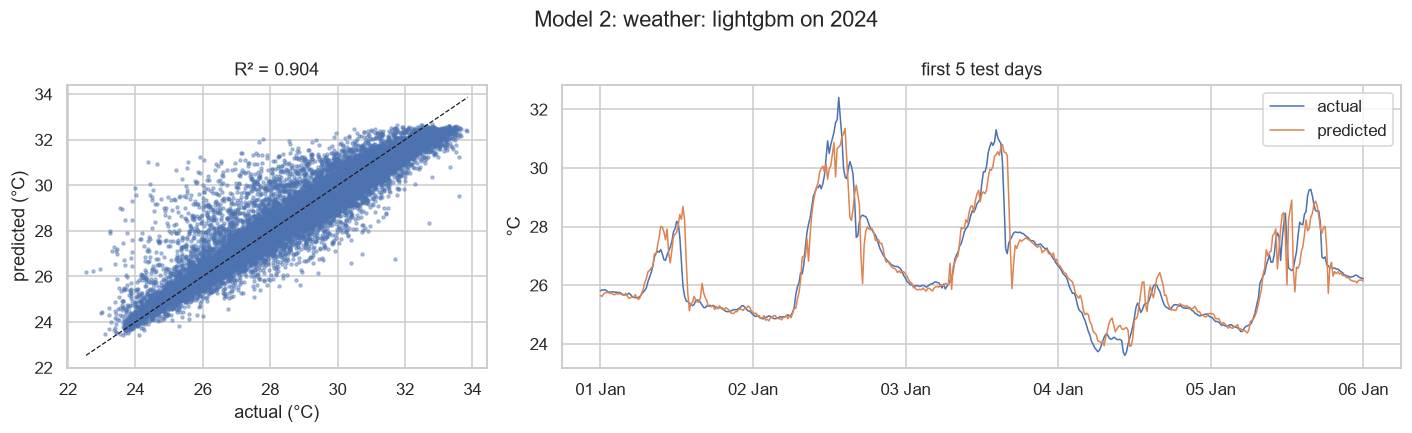

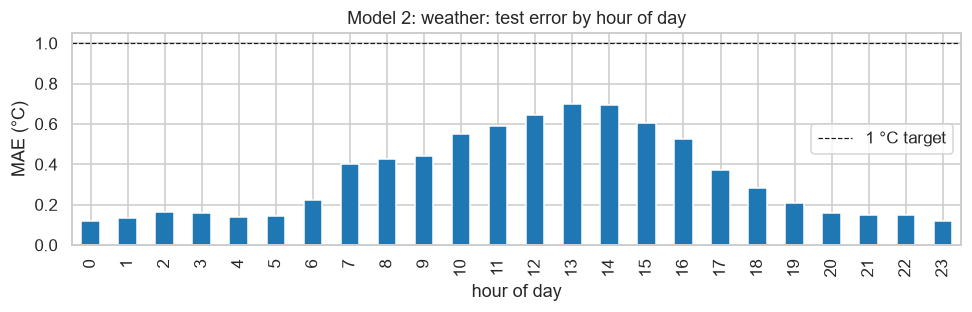

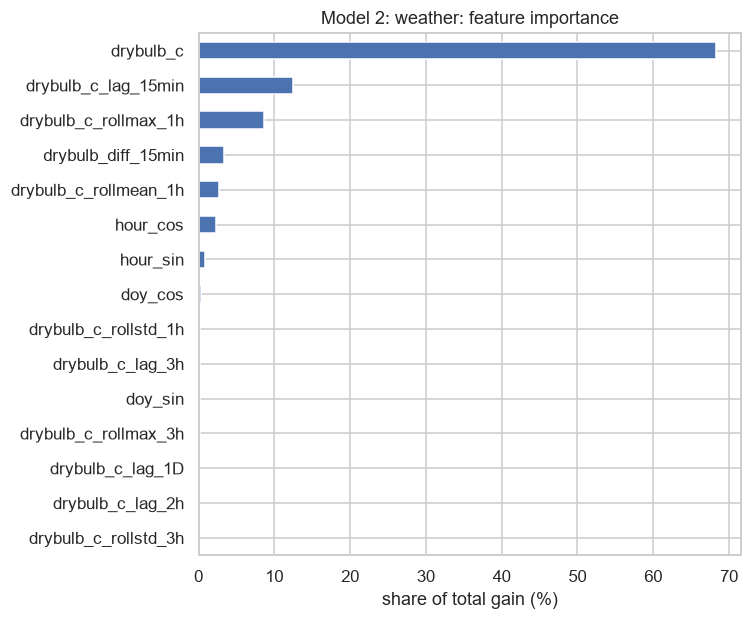

In [58]:
X_te, y_te = m2_data["test"]
p_te = m2_pred[(M2_SELECTED, "test")]
plot_actual_vs_pred(y_te, p_te, f"{M2_TASK}: {M2_SELECTED} on 2024", "°C", "model2_weather_actual_vs_predicted", days=5)

# Error by hour of day: afternoon storms are the hard case (Section 7)
err_by_hour = (p_te - y_te).abs().groupby(y_te.index.hour).mean()
fig, ax = plt.subplots(figsize=(9, 3))
err_by_hour.plot.bar(ax=ax, color="tab:blue")
ax.axhline(1.0, color="k", ls="--", lw=0.8, label="1 °C target")
ax.set_xlabel("hour of day")
ax.set_ylabel("MAE (°C)")
ax.set_title(f"{M2_TASK}: test error by hour of day")
ax.legend()
plt.tight_layout()
save_fig(fig, "model2_weather_error_by_hour")
plt.show()
if M2_SELECTED == "lightgbm":
    m2_importance = plot_importance(m2_fitted["lightgbm"], M2_FEATURES, f"{M2_TASK}: feature importance",
                                    "model2_weather_importance")
TRAINED[M2_TASK] = {"models": m2_fitted, "features": M2_FEATURES, "target": M2_TARGET, "selected": M2_SELECTED,
                    "unit": "°C", "test_actual": y_te, "test_pred": p_te}

## 6. Model 3: Chiller Power Prediction

**Measurements available:** UWCSEA logs **total** chiller energy only, so the model is a **total-power** model. An individual-chiller model needs per-chiller power together with each chiller's load and water temperatures. CSIT has per-chiller kW, but no temperatures in its history and only about 3 days of data, so that model is not trained yet.

**Target:** `Chiller Energy Consumption (kWh)` is energy per 30-min interval, not an instantaneous reading. Section 3.1 divides it by the 0.5 h interval to get the **average kW over the interval** (`chiller_kw`). Percentage errors are the same in kWh-per-interval and in average kW. Absolute errors in kWh per interval are half the kW values.

**Features:** the current operating state in the same interval: building load, chilled-water flow, cooling-water temperature (treated as the condenser water entering the chillers), the implied chilled-water ΔT, and outdoor dry-bulb and wet-bulb. Two terms follow the original code's style: load² and load × cooling-water temperature.

In [59]:
M3_TASK = "Model 3: chiller power"
M3_TARGET = "chiller_kw"


def add_chiller_terms(df):
    df = df.copy()
    df["load_rt_sq"] = df["load_rt"] ** 2
    df["load_x_cw_temp"] = df["load_rt"] * df["cw_temp_c"]
    return df


M3_FEATURES = ["load_rt", "load_rt_sq", "chw_flow_lps", "cw_temp_c", "load_x_cw_temp", "chw_dt_implied_c",
               "drybulb_c", "wetbulb_c"]
m3_splits = {s: add_chiller_terms(df) for s, df in SPLITS["uwcsea"].items()}
m3_data = prepare_xy(m3_splits, M3_FEATURES, M3_TARGET)
m3_models = {**original_model_zoo(), "lightgbm": lightgbm_model()}
m3_fitted, m3_pred, m3_metrics = fit_and_score(M3_TASK, m3_data, m3_models, tol=("rel", 0.03))
M3_SELECTED = select_model(m3_metrics, "MAPE_%")
print("Selected on validation MAPE:", M3_SELECTED)
metric_table(m3_metrics)

Selected on validation MAPE: random_forest


split              train                                                       val                                                      test                                                   
                     MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_% within_tol_%
model                                                                                                                                                                                          
linear_regression 12.548 18.731 0.908  4.898      7.335  0.000       41.584 13.764 19.675 0.921  4.971      7.165 -0.889       38.080 12.785 18.218 0.927  4.569      6.554 -1.993       40.396
ridge             12.540 18.729 0.908  4.896      7.334  0.000       41.831 13.728 19.634 0.921  4.960      7.150 -0.882       38.545 12.751 18.163 0.927  4.563      6.534 -1.979       40.549
random_forest      5.251 10.211 0.973  2.100      3.998 -0.004       79.476  8.928 15.585 0.950  3.399      5.675 -0.429       63.158  9.498 15.179 0.949  3.572      5.460  0.076       60.061
mlp                7.853 13.269 0.954  3.166      5.196  0.359       64.953  9.198 15.490 0.951  3.502      5.641  0.114       61.455 10.015 14.933 0.951  3.733      5.372  0.703       55.335
lightgbm           6.996 11.404 0.966  2.851      4.466  0.006       68.066  9.216 15.517 0.951  3.463      5.651 -0.303       59.752  9.642 14.837 0.952  3.595      5.337  0.145       58.384

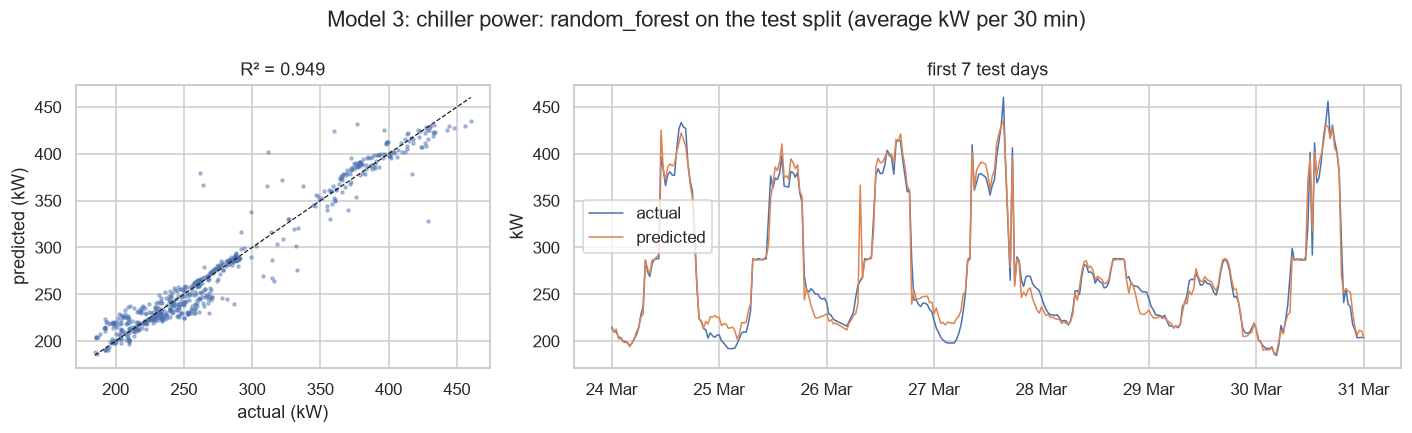

Test energy: actual 91,178 kWh, predicted 91,247 kWh


In [60]:
X_te, y_te = m3_data["test"]
p_te = m3_pred[(M3_SELECTED, "test")]
plot_actual_vs_pred(y_te, p_te, f"{M3_TASK}: {M3_SELECTED} on the test split (average kW per 30 min)", "kW",
                    "model3_chiller_power_actual_vs_predicted")
print(f"Test energy: actual {y_te.sum() * 0.5:,.0f} kWh, predicted {p_te.sum() * 0.5:,.0f} kWh")
if M3_SELECTED == "lightgbm":
    m3_importance = plot_importance(m3_fitted["lightgbm"], M3_FEATURES, f"{M3_TASK}: feature importance",
                                    "model3_chiller_power_importance")
TRAINED[M3_TASK] = {"models": m3_fitted, "features": M3_FEATURES, "target": M3_TARGET, "selected": M3_SELECTED,
                    "unit": "kW", "test_actual": y_te, "test_pred": p_te}

## 7. Model 4: Cooling Tower Temperature Prediction

**Not trained: the required temperature measurements are not confirmed.** This model predicts the tower leaving-water temperature from condenser-water flow and return temperature, fan speed and wet-bulb (Section 7), with a 0.3 °C target. Two gaps block it:

* **UWCSEA**: `Cooling Water Temperature (C)` is a single unlabelled temperature. It is not confirmed as tower leaving water, and there is no return temperature, flow or fan speed to model it from.
* **CSIT**: the tower supply and return temperatures, fan speeds, flows and the wet-bulb exist only in the 131-minute snapshot, and the wet-bulb sensor is faulty.

The check below reads the CSIT point inventory. The model can be trained once the trend holds these points continuously.

In [61]:
def availability(patterns):
    rows = []
    for need, pattern in patterns.items():
        tags = [c for c in csit_columns.index if re.match(pattern, c)]
        info = csit_columns.loc[tags] if tags else pd.DataFrame(columns=csit_columns.columns)
        rows.append({"measurement": need, "CSIT tags": ", ".join(tags) or "none",
                     "max samples": int(info["samples"].max()) if tags else 0,
                     "class": ", ".join(sorted(set(info["class"]))) if tags else "missing"})
    return pd.DataFrame(rows).set_index("measurement")


M4_NEEDS = {
    "tower leaving water temperature": r"^CT\d\.SupTemp$",
    "tower return (entering) temperature": r"^CT\d\.RetTemp$",
    "tower fan speed feedback": r"^CT\d\.[ABC]_Fan_ECFbk$",
    "condenser water flow": r"^(CH\d\.CW_Flow|FLOTECH\.CH\d_CW_Flow)$",
    "outdoor wet-bulb": r"^OA_WetBulbT\.WetBulb_Temp$",
}
M4_AVAILABILITY = availability(M4_NEEDS)
M4_AVAILABILITY

,CSIT tags,max samples,class
measurement,,,
tower leaving water temperature,"CT1.SupTemp, CT2.SupTemp, CT3.SupTemp",66,snapshot
tower return (entering) temperature,"CT1.RetTemp, CT2.RetTemp, CT3.RetTemp",66,snapshot
tower fan speed feedback,"CT1.A_Fan_ECFbk, CT1.B_Fan_ECFbk, CT1.C_Fan_EC...",66,snapshot
condenser water flow,"FLOTECH.CH1_CW_Flow, FLOTECH.CH2_CW_Flow, FLOT...",66,snapshot
outdoor wet-bulb,OA_WetBulbT.WetBulb_Temp,66,snapshot


## 8. Model 5: Pump and Cooling Tower Fan Power Prediction

**Not trained yet.** UWCSEA has no pump or fan power at all. CSIT logs pump and tower-fan **power** in its history, aggregate and per unit, but:

* only about 3 days of it (Section 2.4), so a test window would be a single day;
* the speed and flow that a pump or fan curve is built from exist only in the snapshot;
* several of these meters are faulty: the CHW pump total, CHWP3, and the CT2 and CT3 cells (Section 2.6).

A curve fitted now would only learn three days of operation, with nothing to test it against. The check below shows what exists. The model can be trained once a longer CSIT export with VSD speed and flow is available.

In [62]:
M5_NEEDS = {
    "CHW pump power (per pump)": r"^CHWP\d\.kW$",
    "CW pump power (per pump)": r"^CWP\d\.kWatt$",
    "tower fan power (per cell)": r"^CT\d\.kWatt$",
    "pump / fan power (aggregate)": r"^(CHWP|CWP|CT)\.PMKWtotal$",
    "pump VSD speed feedback": r"^(CHWP|CWP)\d\.VSD(Fbk|Fdk)$",
    "tower fan speed feedback": r"^CT\d\.[ABC]_Fan_ECFbk$",
    "chilled water flow": r"^(CH\d\.CHW_Flow|FLOTECH\.CH\d_CHW_Flow)$",
    "condenser water flow": r"^(CH\d\.CW_Flow|FLOTECH\.CH\d_CW_Flow)$",
}
M5_AVAILABILITY = availability(M5_NEEDS)
M5_AVAILABILITY

,CSIT tags,max samples,class
measurement,,,
CHW pump power (per pump),"CHWP1.kW, CHWP2.kW, CHWP3.kW",5870,trend
CW pump power (per pump),"CWP1.kWatt, CWP2.kWatt, CWP3.kWatt",25402,trend
tower fan power (per cell),"CT1.kWatt, CT2.kWatt, CT3.kWatt",9267,trend
pump / fan power (aggregate),"CHWP.PMKWtotal, CWP.PMKWtotal, CT.PMKWtotal",4686,trend
pump VSD speed feedback,"CWP1.VSDFdk, CWP1.VSDFbk, CWP2.VSDFbk, CWP3.VS...",66,"empty, snapshot"
tower fan speed feedback,"CT1.A_Fan_ECFbk, CT1.B_Fan_ECFbk, CT1.C_Fan_EC...",66,snapshot
chilled water flow,"FLOTECH.CH1_CHW_Flow, FLOTECH.CH2_CHW_Flow, FL...",66,snapshot
condenser water flow,"FLOTECH.CH1_CW_Flow, FLOTECH.CH2_CW_Flow, FLOT...",66,snapshot


## 9. Model 6: Whole-Plant Energy Baseline Prediction

The baseline predicts the energy the plant is expected to use **under the observed conditions** (Section 7): cooling load, outdoor temperature and humidity, time of day and day of week. Unlike Model 3, it deliberately leaves out cooling-water temperature and chilled-water flow. Those follow the setpoints, and the baseline must represent today's setpoints whatever the operator does later.

**Scope with the data available now:** UWCSEA meters chiller energy only, so this is a **chiller-energy baseline**, not a whole-plant one; pumps and towers are not metered. It is fitted on the pre-COVID weeks, as Section 7 fits it on data from before the recommendations start. The model with the lowest validation CV(RMSE) is selected, and the test split checks the Section 7 tolerance as total energy over the test period (NMBE), the two statistics ASHRAE Guideline 14 uses for baselines. The baseline is then run over the circuit-breaker weeks to show how the monthly saving report works: expected minus metered energy.

In [63]:
M6_TASK = "Model 6: energy baseline"
M6_TARGET = "chiller_kw"
M6_FEATURES = ["load_rt", "drybulb_c", "wetbulb_c", "rh_pct_at_drybulb",
               "hour_sin", "hour_cos", "dow_sin", "dow_cos", "is_workday", "is_holiday"]
m6_data = prepare_xy(SPLITS["uwcsea"], M6_FEATURES, M6_TARGET)
m6_models = {**original_model_zoo(), "lightgbm": lightgbm_model()}
m6_fitted, m6_pred, m6_metrics = fit_and_score(M6_TASK, m6_data, m6_models, tol=("rel", 0.05))
# Baselines are selected on CV(RMSE) and accepted on NMBE, the two statistics of ASHRAE Guideline 14
M6_SELECTED = select_model(m6_metrics, "CV(RMSE)_%")
print("Selected on validation CV(RMSE):", M6_SELECTED)
metric_table(m6_metrics, ("MAE", "RMSE", "R2", "MAPE_%", "CV(RMSE)_%", "NMBE_%"))

Selected on validation CV(RMSE): lightgbm


split              train                                          val                                         test                                      
                     MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_%    MAE   RMSE    R2 MAPE_% CV(RMSE)_% NMBE_%
model                                                                                                                                                   
linear_regression 18.739 23.651 0.852  7.271      9.265  0.000 20.323 24.685 0.875  7.266      8.999 -0.550 19.410 23.002 0.884  6.796      8.275 -1.622
ridge             18.747 23.651 0.852  7.274      9.265 -0.000 20.333 24.691 0.875  7.268      9.001 -0.554 19.419 23.014 0.883  6.798      8.279 -1.625
random_forest      7.490 12.435 0.959  2.964      4.871  0.024 13.024 18.782 0.927  4.878      6.847 -1.141 11.942 16.926 0.937  4.382      6.089 -2.020
mlp               10.757 15.907 0.933  4.252      6.231 -0.160 13.728 19.347 0.923  5.110      7.053 -0.736 12.878 17.365 0.934  4.724      6.247 -1.799
lightgbm           9.701 14.500 0.944  3.880      5.680  0.002 13.201 18.700 0.928  4.928      6.817 -1.257 12.122 16.758 0.938  4.465      6.029 -2.085

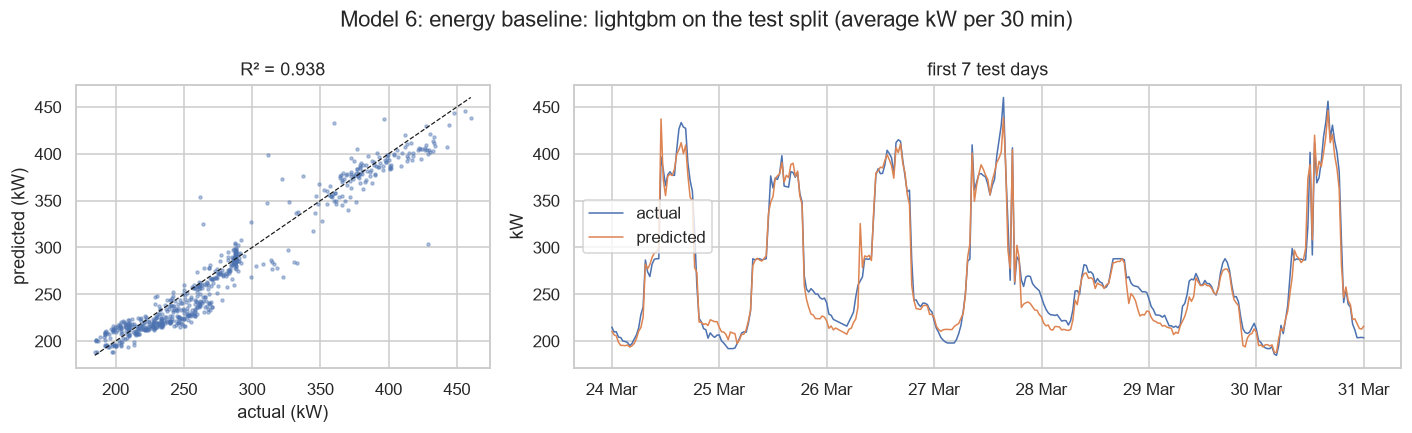

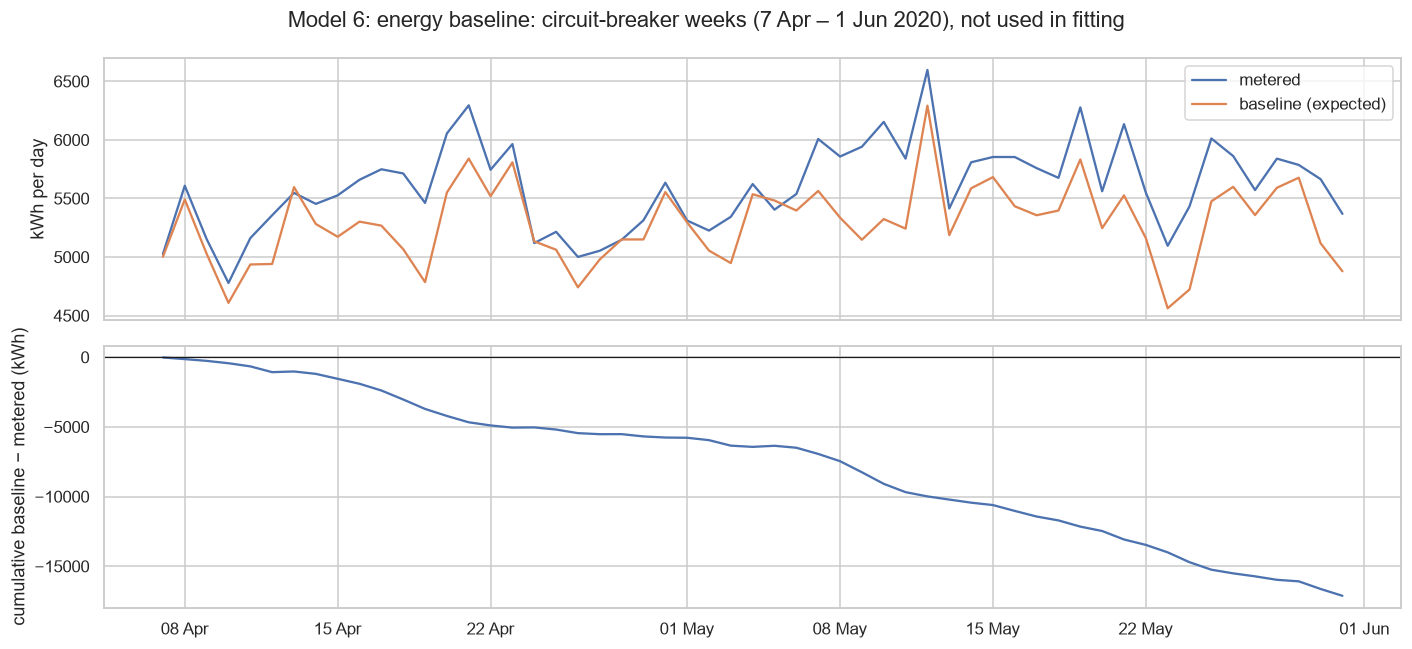

Metered 308,095 kWh vs baseline 290,973 kWh (-5.9 % of baseline)


In [64]:
X_te, y_te = m6_data["test"]
p_te = m6_pred[(M6_SELECTED, "test")]
plot_actual_vs_pred(y_te, p_te, f"{M6_TASK}: {M6_SELECTED} on the test split (average kW per 30 min)", "kW",
                    "model6_baseline_actual_vs_predicted")
TRAINED[M6_TASK] = {"models": m6_fitted, "features": M6_FEATURES, "target": M6_TARGET, "selected": M6_SELECTED,
                    "unit": "kW", "test_actual": y_te, "test_pred": p_te}

# Saving-report mechanics on the circuit-breaker weeks: expected (baseline) vs metered energy
Xs, ys = prepare_xy({"rs": uw_regime_shift}, M6_FEATURES, M6_TARGET)["rs"]
expected = pd.Series(m6_fitted[M6_SELECTED].predict(Xs), index=Xs.index)
daily = pd.DataFrame({"metered_kWh": ys * 0.5, "baseline_kWh": expected * 0.5}).resample("D").sum(min_count=40)
daily["difference_kWh"] = daily["baseline_kWh"] - daily["metered_kWh"]
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(daily.index, daily["metered_kWh"], label="metered")
axes[0].plot(daily.index, daily["baseline_kWh"], label="baseline (expected)")
axes[0].set_ylabel("kWh per day")
axes[0].legend()
axes[1].plot(daily.index, daily["difference_kWh"].cumsum())
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_ylabel("cumulative baseline − metered (kWh)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=LOCAL_TZ))
fig.suptitle(f"{M6_TASK}: circuit-breaker weeks (7 Apr – 1 Jun 2020), not used in fitting")
plt.tight_layout()
save_fig(fig, "model6_baseline_regime_shift")
plt.show()
total = daily[["metered_kWh", "baseline_kWh"]].sum()
print(f"Metered {total['metered_kWh']:,.0f} kWh vs baseline {total['baseline_kWh']:,.0f} kWh "
      f"({100 * (total['baseline_kWh'] - total['metered_kWh']) / total['baseline_kWh']:+.1f} % of baseline)")

## 10. Model Accuracy Comparison

MAE, RMSE and R² for each trained model on the test split, with the Section 7 acceptance check and an actual-versus-predicted chart. Models 4 and 5 are listed as not trained.

In [65]:
metrics_all = pd.concat(ALL_METRICS, ignore_index=True)
rows = []
for task in ACCEPTANCE.index:
    acc = ACCEPTANCE.loc[task]
    if task not in TRAINED:
        rows.append({"task": task, "model": "not trained", "acceptance": f"{acc['metric']} ≤ {acc['limit']:g}",
                     "result": "no data"})
        continue
    sel = TRAINED[task]["selected"]
    r = metrics_all[(metrics_all["task"] == task) & (metrics_all["model"] == sel) & (metrics_all["split"] == "test")].iloc[0]
    rows.append({"task": task, "model": sel, "n": int(r["n"]), "MAE": r["MAE"], "RMSE": r["RMSE"], "R2": r["R2"],
                 "MAPE_%": r["MAPE_%"], "NMBE_%": r["NMBE_%"], "acceptance": f"{acc['metric']} ≤ {acc['limit']:g}",
                 "value": r[acc["metric"]], "result": "pass" if r[acc["metric"]] <= acc["limit"] else "fail"})
SUMMARY = pd.DataFrame(rows).set_index("task")
units = {t: v["unit"] for t, v in TRAINED.items()}
SUMMARY.insert(1, "unit", pd.Series(units))
SUMMARY

,model,unit,n,MAE,RMSE,R2,MAPE_%,NMBE_%,acceptance,value,result
task,,,,,,,,,,,
Model 1: cooling load,lightgbm,RT,650.000,18.384,26.291,0.930,3.154,0.642,MAPE_% ≤ 5,3.154,pass
Model 2: weather,lightgbm,°C,"34,709.000",0.338,0.585,0.904,1.190,-0.176,MAE ≤ 1,0.338,pass
Model 3: chiller power,random_forest,kW,656.000,9.498,15.179,0.949,3.572,0.076,MAPE_% ≤ 3,3.572,fail
Model 4: cooling tower,not trained,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MAE ≤ 0.3,NaN,no data
Model 5: pump and fan power,not trained,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MAPE_% ≤ 3,NaN,no data
Model 6: energy baseline,lightgbm,kW,656.000,12.122,16.758,0.938,4.465,-2.085,|NMBE|_% ≤ 5,2.085,pass


In [66]:
# Test-split comparison of every model, per task
test_cmp = metrics_all[metrics_all["split"] == "test"].pivot_table(index="model", columns="task", values=["MAE", "RMSE", "R2"])
test_cmp = test_cmp.reorder_levels([1, 0], axis=1).sort_index(axis=1)
test_cmp

task              Model 1: cooling load              Model 2: weather             Model 3: chiller power              Model 6: energy baseline             
                                    MAE    R2   RMSE              MAE    R2  RMSE                    MAE    R2   RMSE                      MAE    R2   RMSE
model                                                                                                                                                      
lightgbm                         18.384 0.930 26.291            0.338 0.904 0.585                  9.642 0.952 14.837                   12.122 0.938 16.758
linear_regression                23.965 0.887 33.370            0.382 0.892 0.621                 12.785 0.927 18.218                   19.410 0.884 23.002
mlp                              22.412 0.910 29.774              NaN   NaN   NaN                 10.015 0.951 14.933                   12.878 0.934 17.365
persistence                      29.126 0.806 43.692            0.470 0.851 0.731                    NaN   NaN    NaN                      NaN   NaN    NaN
random_forest                    18.400 0.930 26.255              NaN   NaN   NaN                  9.498 0.949 15.179                   11.942 0.937 16.926
ridge                            23.961 0.887 33.367            0.382 0.892 0.621                 12.751 0.927 18.163                   19.419 0.883 23.014

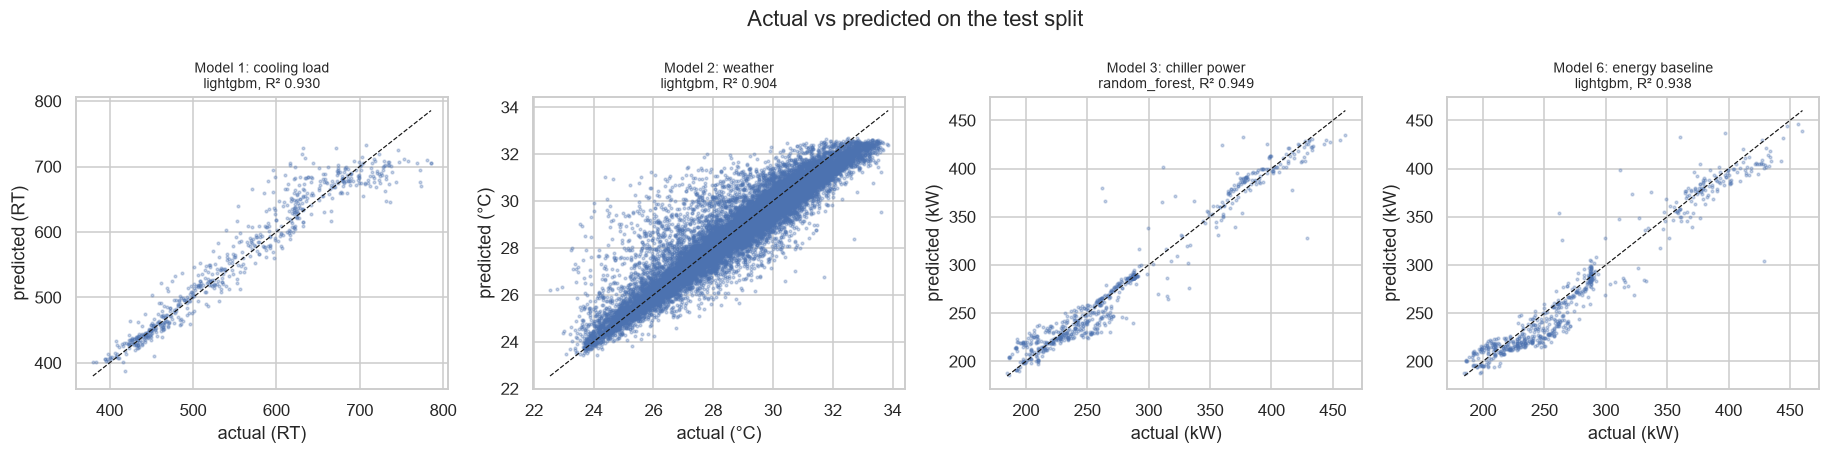

In [67]:
fig, axes = plt.subplots(1, len(TRAINED), figsize=(4.2 * len(TRAINED), 4.2))
for ax, (task, t) in zip(np.atleast_1d(axes), TRAINED.items()):
    y, p = t["test_actual"], t["test_pred"]
    ax.scatter(y, p, s=3, alpha=0.3)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_title(f"{task}\n{t['selected']}, R² {r2_score(y, p):.3f}", fontsize=9)
    ax.set_xlabel(f"actual ({t['unit']})")
    ax.set_ylabel(f"predicted ({t['unit']})")
fig.suptitle("Actual vs predicted on the test split")
plt.tight_layout()
save_fig(fig, "comparison_actual_vs_predicted")
plt.show()

### Reading the results

| Model | Test result | Against Section 7 |
|---|---|---|
| 1 Cooling load | LightGBM: MAPE 3.2 %, R² 0.93; 81 % of half-hours within ± 5 %. Persistence: MAPE 5.1 % | **pass** |
| 2 Weather (dry-bulb) | LightGBM: MAE 0.34 °C on 2024; 93 % of forecasts within 1 °C. Persistence: 0.47 °C | **pass** (dry-bulb only) |
| 3 Chiller power | Random forest: MAPE 3.6 %, R² 0.95; total test energy within 0.1 % | **fails** the 3 % target, narrowly |
| 4 Cooling tower | not trained: no confirmed temperature history | — |
| 5 Pump and fan power | not trained: about 3 days of CSIT data, with no speed or flow | — |
| 6 Energy baseline | LightGBM: NMBE −2.1 %, CV(RMSE) 6.0 % | **pass** |

**Model 1.** Random forest and LightGBM are close on every split. Both cut persistence's error by about a third, and the morning ramp and the afternoon peak are followed well. In the circuit-breaker weeks, however, every trained model does worse (MAPE 7.5 – 13 %) than plain persistence (4.6 %). The models learned the pre-COVID occupancy pattern. A change in building use therefore needs a refit, as Section 12 says, and persistence is a sensible fallback while the model catches up.

**Model 2.** The forecast is well inside the 1 °C target on average. The largest errors fall in the early afternoon, when showers and storms are likely, which matches the Section 7 note on afternoon storms. Two limits remain: it is trained on NEA stations 4 – 6 km from CSIT rather than the station at the towers, and the humidity / wet-bulb forecast cannot be trained until a working humidity sensor is available.

**Model 3.** The model is close to the target, and accurate on total energy, but the half-hourly error is above 3 %. UWCSEA gives only the plant's total chiller energy, with no chilled-water supply temperature and no record of which chillers ran. So the model cannot separate staging changes from load changes, and it cannot show the effect of the setpoint, which is the reason the model exists. The Section 7 version, one curve per chiller with CHWS and CWS temperatures as inputs, needs that data from CSIT.

**Model 6.** The baseline reproduces total energy over the 14 test days within 2.1 %. CV(RMSE) of 6 % is well inside the 30 % that ASHRAE Guideline 14 allows for hourly baselines. Over the circuit-breaker weeks the plant used **5.9 % more** energy than the baseline expects for the observed load and weather. A saving report would show that as a negative saving. This illustrates the report mechanics, not a measured result: a change in building use is exactly the case where Section 12 says the baseline must be refitted.

**Caveat on transfer.** Models 1, 3 and 6 are fitted on UWCSEA, a different building and plant from CSIT. They show the method and the accuracy that is achievable on a few months of 30-min data. For CSIT they must be refitted on CSIT's own history once a continuous export is available.

## 11. Results Export

Everything a Word report needs is written to `results/`:

| Folder / file | Content |
|---|---|
| `figures/*.png` | every chart from Sections 4 – 10, at 200 dpi |
| `tables/*.csv`, `tables/results_tables.xlsx` | accuracy summary, all metrics, acceptance rules, data availability, feature importance (one sheet each in the workbook) |
| `tables/test_predictions_*.csv` | actual and predicted values on each test split |
| `models/*.joblib` | every trained model, with a `*_card.json` per task listing features, target, selected model and test metrics |

In [68]:
exported = []

# Models and model cards
for task, t in TRAINED.items():
    slug = re.sub(r"[^a-z0-9]+", "_", task.lower()).strip("_")
    for name, model in t["models"].items():
        path = MODEL_DIR / f"{slug}__{name}.joblib"
        joblib.dump(model, path, compress=3)
        exported.append(path)
    test_row = SUMMARY.loc[task].dropna().to_dict()
    card = {"task": task, "target": t["target"], "unit": t["unit"], "features": t["features"],
            "selected_model": t["selected"], "test_metrics": test_row,
            "test_period": [str(t["test_actual"].index.min()), str(t["test_actual"].index.max())]}
    card_path = MODEL_DIR / f"{slug}_card.json"
    card_path.write_text(json.dumps(card, indent=2, default=str), encoding="utf-8")
    exported.append(card_path)
    pd.DataFrame({"actual": t["test_actual"], "predicted": t["test_pred"]}).to_csv(TABLE_DIR / f"test_predictions_{slug}.csv")
    exported.append(TABLE_DIR / f"test_predictions_{slug}.csv")

# Tables
importance = {k: v for k, v in {"Model 1": globals().get("m1_importance"), "Model 2": globals().get("m2_importance"),
                                "Model 3": globals().get("m3_importance")}.items() if v is not None}
tables = {
    "accuracy_summary": SUMMARY.reset_index(),
    "metrics_all": metrics_all,
    "acceptance_rules": ACCEPTANCE.reset_index(),
    "model4_data_availability": M4_AVAILABILITY.reset_index(),
    "model5_data_availability": M5_AVAILABILITY.reset_index(),
    "split_summary": summary.reset_index(),
    "feature_importance": pd.concat(importance, names=["task", "feature"]).rename("gain_%").reset_index() if importance else pd.DataFrame(),
}
for name, df in tables.items():
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    exported.append(TABLE_DIR / f"{name}.csv")


def excel_safe(df):
    out = df.copy()
    for c in out.columns:
        if isinstance(out[c].dtype, pd.DatetimeTZDtype):
            out[c] = out[c].dt.tz_localize(None)
    return out


with pd.ExcelWriter(TABLE_DIR / "results_tables.xlsx") as xw:
    for name, df in tables.items():
        excel_safe(df).to_excel(xw, sheet_name=name[:31], index=False)
exported.append(TABLE_DIR / "results_tables.xlsx")

manifest = pd.DataFrame({"file": [str(p.relative_to(RESULTS_DIR)) for p in exported] + [f"figures/{f}" for f in FIGURES]})
manifest["size_kB"] = [round((RESULTS_DIR / f).stat().st_size / 1024, 1) for f in manifest["file"]]
print(f"{len(manifest)} files written to {RESULTS_DIR}")
manifest

43 files written to D:\GitHub\Roycemedia\model-validation-v1\results


,file,size_kB
0,models\model_1_cooling_load__linear_regression...,1.100
1,models\model_1_cooling_load__ridge.joblib,0.900
2,models\model_1_cooling_load__random_forest.joblib,"12,724.800"
3,models\model_1_cooling_load__mlp.joblib,170.100
4,models\model_1_cooling_load__lightgbm.joblib,233.800
5,models\model_1_cooling_load_card.json,1.100
6,tables\test_predictions_model_1_cooling_load.csv,32.400
7,models\model_2_weather__linear_regression.joblib,1.000
8,models\model_2_weather__ridge.joblib,0.800
9,models\model_2_weather__lightgbm.joblib,358.200
